In [33]:
import pandas as pd
import numpy as np
df=pd.read_csv("dataset_work.csv")
df=df.sort_values(["Region Code","Time"]).copy()
df=df[df["Time"]>=1950]
pop="Total population (Both sexes)【person】"
df["Population Growth Rate (%)"] = (df.groupby("Region Code")[pop].pct_change()*100)
df["Population Decline"]=np.where(df["Population Growth Rate (%)"].notna(),(df["Population Growth Rate (%)"]<0).astype(int),np.nan)

In [34]:
print(df["Population Growth Rate (%)"].describe())
print()
print(df["Population Decline"].value_counts(dropna=False))

count    2425.000000
mean        0.012834
std         0.666215
min        -2.112017
25%        -0.434573
50%        -0.008412
75%         0.436899
max         2.958928
Name: Population Growth Rate (%), dtype: float64

Population Decline
1.0    1220
0.0    1205
NaN      48
Name: count, dtype: int64


In [35]:
print(df[["Time","Region",pop,"Population Growth Rate (%)","Population Decline"]].head(20))

    Time Region  Total population (Both sexes)【person】  \
6   1950  Japan                               84114574   
7   1951  Japan                               84541000   
8   1952  Japan                               85808000   
9   1953  Japan                               86981000   
10  1954  Japan                               88239000   
11  1955  Japan                               90076594   
12  1956  Japan                               90172000   
13  1957  Japan                               90928000   
14  1958  Japan                               91767000   
15  1959  Japan                               92641000   
16  1960  Japan                               94301623   
17  1961  Japan                               94287000   
18  1962  Japan                               95181000   
19  1963  Japan                               96156000   
20  1964  Japan                               97182000   
21  1965  Japan                               99209137   
22  1966  Japa

In [36]:
#Core Derived Variables
#Natural population change
df["Natural Change"]=(df["Live births【person】"]-  df["Deaths【person】"])

#Overall net migration
df["Net Migration"]=(df["Total in-migrants (overall)【person】"]-df["Total out-migrants (overall)【person】"])
df["Birth Rate"]=(df["Live births【person】"]/df[pop]*1000)
df["Death Rate"]=(df["Deaths【person】"]/df[pop]*1000)
df["Net Migration Rate"]=df["Net Migration"]/df[pop]*1000
df["Dependency Ratio"]=(df["Percentage distribution of total population (0-14)【%】"]+df["Percentage distribution of total population (65 and over)【%】"])/df["Percentage distribution of total population (15-64)【%】"]*100
df["Population Density"]=df[pop]/df["Area (km²)"]

#DID population
df["DID share (%)"]=df["DID Population【person】"]/df[pop]*100
derived_vars=["Population Growth Rate (%)","Population Decline","Natural Change","Net Migration","Birth Rate","Death Rate","Net Migration Rate","Dependency Ratio","Population Density","DID share (%)"]
print(df[derived_vars].describe().T)


                             count        mean           std            min  \
Population Growth Rate (%)  2425.0    0.012834      0.666215      -2.112017   
Population Decline          2425.0    0.503093      0.500094       0.000000   
Natural Change              1505.0 -485.478405  92793.229005 -919205.000000   
Net Migration                576.0    0.000000  11736.351336  -11409.000000   
Birth Rate                  1505.0    7.976973      1.508988       3.567623   
Death Rate                  2445.0    9.101214      2.680740       4.128325   
Net Migration Rate           576.0   -1.571974      2.012946      -5.507913   
Dependency Ratio             991.0   66.810778     10.336622      42.836469   
Population Density          2473.0  618.947132   1093.579108      59.761248   
DID share (%)                480.0   49.554907     18.700475      21.849143   

                                    25%          50%          75%  \
Population Growth Rate (%)    -0.434573    -0.008412     0.43

In [37]:
checks={
    "Birth Rate < 0": (df["Birth Rate"]<0).sum(),
    "Death Rate < 0": (df["Death Rate"]<0).sum(),
    "Dependency Ratio < 0": (df["Dependency Ratio"]<0).sum(),
    "DID share > 100": (df["DID share (%)"]>100).sum(),
    "DID share < 0": (df["DID share (%)"]<0).sum(),
    "Population Density < 0": (df["Population Density"]<0).sum()
}
print(checks)

{'Birth Rate < 0': np.int64(0), 'Death Rate < 0': np.int64(0), 'Dependency Ratio < 0': np.int64(0), 'DID share > 100': np.int64(0), 'DID share < 0': np.int64(0), 'Population Density < 0': np.int64(0)}


In [38]:
analysis_vars = [
    "Population Growth Rate (%)",
    "Population Decline",
    "Total fertility rate",
    "Natural Change",
    "Net Migration",
    "Birth Rate",
    "Death Rate",
    "Net Migration Rate",
    "Dependency Ratio",
    "Population Density",
    "DID share (%)",
    "Prefectural income per person (2015 base)[thousand yen]",
    "Monthly household income (2+ person workers' households)[yen]",
    "Unemployment rate (Both sexes)[%]",
    "Life expectancy (Male)[years]",
    "Life expectancy (Female)[years]",
    "Crude marriage rates (per 1,000 population)",
    "Crude divorce rates (per 1,000 population)"
]

df[analysis_vars].describe().T


,count,mean,std,min,25%,50%,75%,max
Population Growth Rate (%),2425.0,0.012834,0.666215,-2.112017,-0.434573,-0.008412,0.436899,2.958928e+00
Population Decline,2425.0,0.503093,0.500094,0.000000,0.000000,1.000000,1.000000,1.000000e+00
Total fertility rate,1975.0,1.480278,0.187142,0.960000,1.360000,1.470000,1.600000,2.310000e+00
Natural Change,1505.0,-485.478405,92793.229005,-919205.000000,-7986.000000,-3114.000000,842.000000,1.012822e+06
Net Migration,576.0,0.000000,11736.351336,-11409.000000,-4321.000000,-2480.500000,-1013.250000,8.423100e+04
Birth Rate,1505.0,7.976973,1.508988,3.567623,6.996785,8.137028,8.971003,1.483326e+01
Death Rate,2445.0,9.101214,2.680740,4.128325,7.214905,8.454666,10.700279,1.942140e+01
Net Migration Rate,576.0,-1.571974,2.012946,-5.507913,-2.915538,-1.909309,-0.562058,6.232283e+00
Dependency Ratio,991.0,66.810778,10.336622,42.836469,59.872077,66.112957,74.216028,9.360465e+01
Population Density,2473.0,618.947132,1093.579108,59.761248,180.853629,270.435902,469.717796,6.475731e+03


In [39]:
missing_summary=df[analysis_vars].isna().sum()
print("Missing values summary:", missing_summary)
missing_summary_pct=df[analysis_vars].isna().mean()*100
print("Missing values percentage summary:", missing_summary_pct)

Missing values summary: Population Growth Rate (%)                                         48
Population Decline                                                 48
Total fertility rate                                              498
Natural Change                                                    968
Net Migration                                                    1897
Birth Rate                                                        968
Death Rate                                                         28
Net Migration Rate                                               1897
Dependency Ratio                                                 1482
Population Density                                                  0
DID share (%)                                                    1993
Prefectural income per person (2015 base)[thousand yen]          1993
Monthly household income (2+ person workers' households)[yen]      25
Unemployment rate (Both sexes)[%]                                1

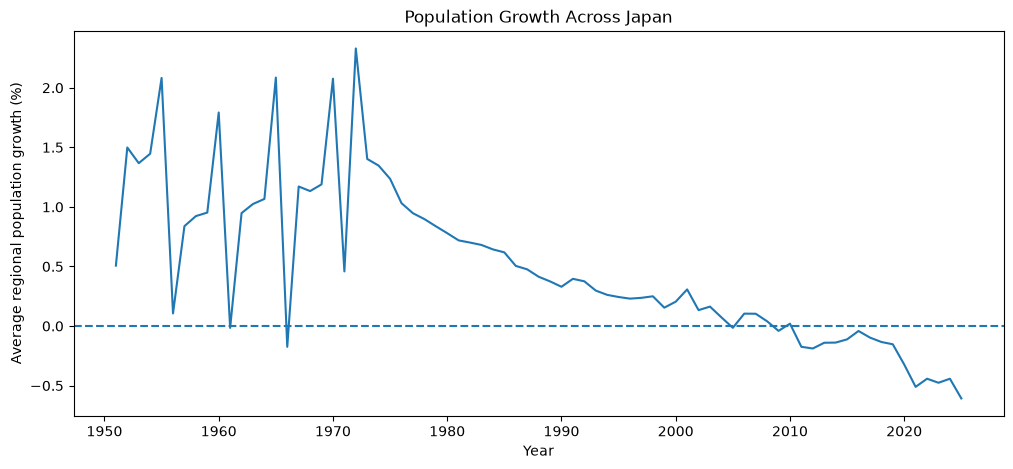

Time
2006    0.104100
2007    0.103205
2008    0.039833
2009   -0.040598
2010    0.019801
2011   -0.174416
2012   -0.188526
2013   -0.140290
2014   -0.138917
2015   -0.111803
2016   -0.041501
2017   -0.096818
2018   -0.133944
2019   -0.153058
2020   -0.323101
2021   -0.510598
2022   -0.442224
2023   -0.476202
2024   -0.442293
2025   -0.607806
Name: Population Growth Rate (%), dtype: float64


In [40]:
import matplotlib.pyplot as plt
national_df=df[df["Region Code"]==0].copy()
national_growth_by_year=national_df.groupby("Time")["Population Growth Rate (%)"].mean()
plt.figure(figsize=(12,5))
plt.plot(national_growth_by_year.index,national_growth_by_year.values)
plt.axhline(0,linestyle="--")
plt.xlabel("Year")
plt.ylabel("Average regional population growth (%)")
plt.title("Population Growth Across Japan")
plt.show()
print(national_growth_by_year.tail(20))

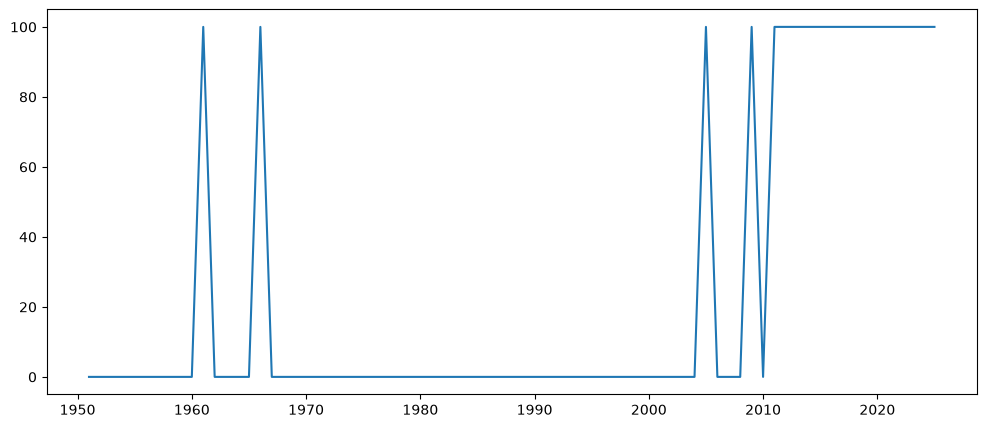

In [41]:
decline_by_year_national=(national_df.groupby("Time")["Population Decline"]).mean()*100;
plt.figure(figsize=(12,5))
plt.plot(decline_by_year_national.index,decline_by_year_national.values)

In [42]:
regional_df=df[df["Region Code"]!=0].copy()
growth_by_year=regional_df.groupby("Time")["Population Growth Rate (%)"].mean()
print("Average population growth by year:")
print(growth_by_year.tail(20))

Average population growth by year:
Time
2006   -0.189115
2007   -0.211938
2008   -0.286741
2009   -0.292528
2010   -0.248597
2011   -0.391002
2012   -0.388425
2013   -0.385661
2014   -0.413005
2015   -0.426064
2016   -0.358105
2017   -0.421661
2018   -0.472186
2019   -0.514573
2020   -0.611334
2021   -0.732349
2022   -0.717263
2023   -0.818421
2024   -0.838595
2025   -1.065903
Name: Population Growth Rate (%), dtype: float64


Text(0, 0.5, 'Average population growth (%)')

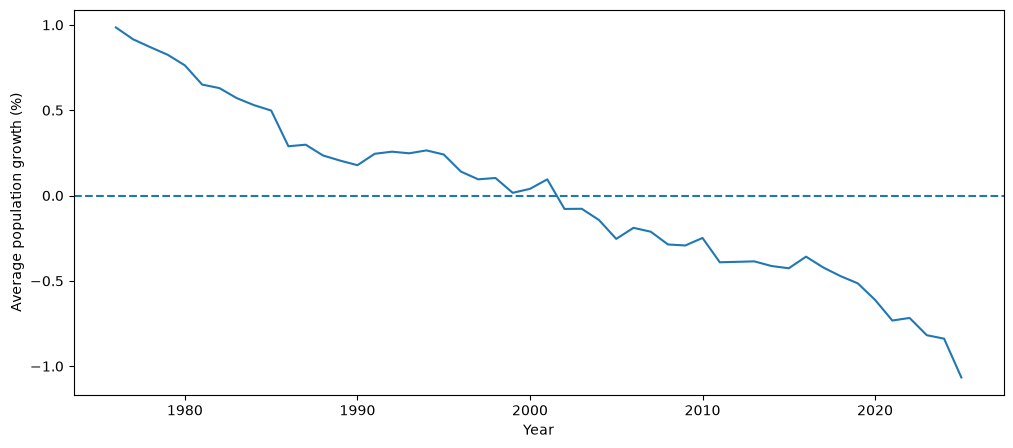

In [43]:

plt.figure(figsize=(12,5))
plt.plot(growth_by_year.index,growth_by_year.values)
plt.axhline(0,linestyle="--")
plt.xlabel("Year")
plt.ylabel("Average population growth (%)")

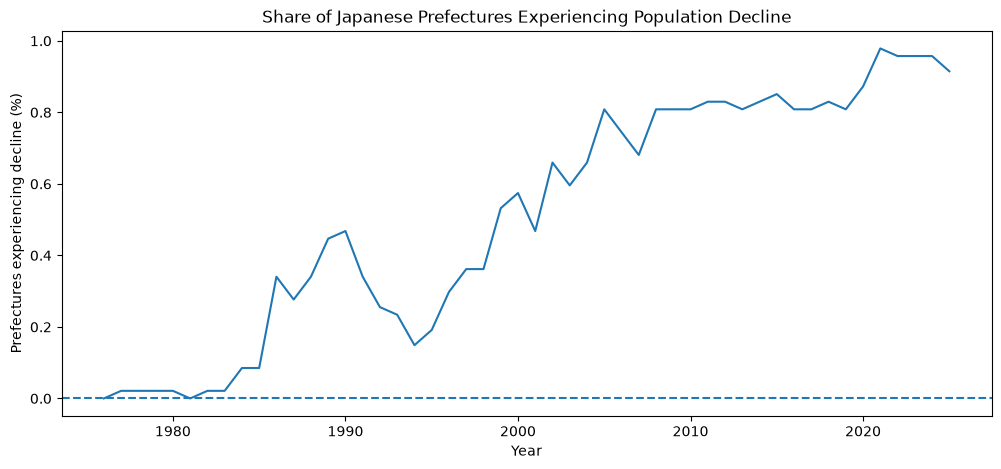

In [44]:
decline_by_year=(regional_df.groupby("Time")["Population Decline"].mean())
plt.figure(figsize=(12,5))
plt.plot(decline_by_year.index,decline_by_year.values)
plt.axhline(0,linestyle="--")
plt.xlabel("Year")
plt.ylabel("Prefectures experiencing decline (%)")
plt.title("Share of Japanese Prefectures Experiencing Population Decline")

plt.show()

In [45]:
#Latest year ranking
latest_year=df["Time"].max()
print("Latest year: ",latest_year)
latest=(regional_df[regional_df["Time"]==latest_year][["Region","Population Growth Rate (%)","Population Decline"]].sort_values("Population Growth Rate (%)"))
print("10 fastest-growing prefectures:")
print(latest.tail(10))
print("10 slowest-growing prefectures:")
print(latest.head(10))


Latest year:  2025
10 fastest-growing prefectures:
            Region  Population Growth Rate (%)  Population Decline
2442   Saitama-ken                   -0.611443                 1.0
2439   Ibaraki-ken                   -0.527192                 1.0
2445  Kanagawa-ken                   -0.339762                 1.0
2459     Hyogo-ken                   -0.246862                 1.0
2471   Fukuoka-ken                   -0.198763                 1.0
2454     Aichi-ken                   -0.142051                 1.0
2458      Osaka-fu                    0.086536                 0.0
2443     Chiba-ken                    0.120173                 0.0
2478   Okinawa-ken                    0.151432                 0.0
2444      Tokyo-to                    0.481161                 0.0
10 slowest-growing prefectures:
             Region  Population Growth Rate (%)  Population Decline
2433     Aomori-ken                   -2.112017                 1.0
2463    Shimane-ken                   -1.953

In [46]:
declining_count=regional_df.groupby("Time")["Population Decline"].sum()
print("Number of prefectures experiencing population decline by year:")
print(declining_count.tail(20))

Number of prefectures experiencing population decline by year:
Time
2006    35.0
2007    32.0
2008    38.0
2009    38.0
2010    38.0
2011    39.0
2012    39.0
2013    38.0
2014    39.0
2015    40.0
2016    38.0
2017    38.0
2018    39.0
2019    38.0
2020    41.0
2021    46.0
2022    45.0
2023    45.0
2024    45.0
2025    43.0
Name: Population Decline, dtype: float64


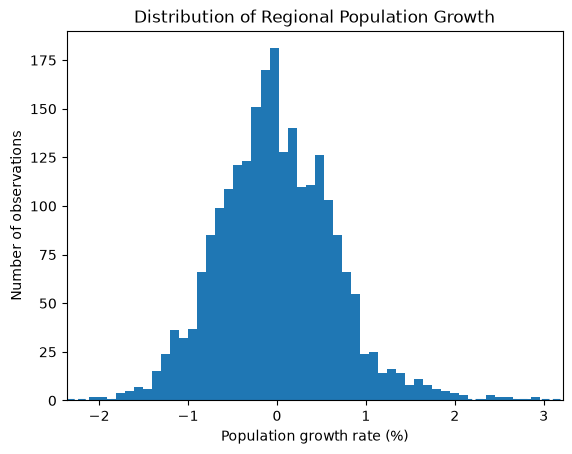

In [47]:
plt.hist(regional_df["Population Growth Rate (%)"].dropna(),bins=50)
plt.axhline(0,linestyle="--")
plt.xlabel("Population growth rate (%)")
plt.ylabel("Number of observations")
plt.title("Distribution of Regional Population Growth")

plt.show()

In [48]:
derived_vars = [
    "Population Growth Rate (%)",
    "Population Decline",
    "Natural Change",
    "Net Migration",
    "Birth Rate",
    "Death Rate",
    "Net Migration Rate",
    "Dependency Ratio",
    "Population Density",
    "DID share (%)"
]

print(df[derived_vars].describe().T)

                             count        mean           std            min  \
Population Growth Rate (%)  2425.0    0.012834      0.666215      -2.112017   
Population Decline          2425.0    0.503093      0.500094       0.000000   
Natural Change              1505.0 -485.478405  92793.229005 -919205.000000   
Net Migration                576.0    0.000000  11736.351336  -11409.000000   
Birth Rate                  1505.0    7.976973      1.508988       3.567623   
Death Rate                  2445.0    9.101214      2.680740       4.128325   
Net Migration Rate           576.0   -1.571974      2.012946      -5.507913   
Dependency Ratio             991.0   66.810778     10.336622      42.836469   
Population Density          2473.0  618.947132   1093.579108      59.761248   
DID share (%)                480.0   49.554907     18.700475      21.849143   

                                    25%          50%          75%  \
Population Growth Rate (%)    -0.434573    -0.008412     0.43

In [49]:
predictors = [
    "Total fertility rate",
        "Natural Change",
        "Net Migration",
        "Birth Rate",
        "Death Rate",
        "Net Migration Rate",
        "Dependency Ratio",
        "Population Density",
        "DID share (%)",
        "Prefectural income per person (2015 base)[thousand yen]",
        "Monthly household income (2+ person workers' households)[yen]",
        "Unemployment rate (Both sexes)[%]",
        "Life expectancy (Male)[years]",
        "Life expectancy (Female)[years]",
        "Crude marriage rates (per 1,000 population)",
        "Crude divorce rates (per 1,000 population)"
]
corr=regional_df[["Population Growth Rate (%)"]+predictors].corr()
corr["Population Growth Rate (%)"].sort_values()


Death Rate                                                      -0.860280
Dependency Ratio                                                -0.791721
Life expectancy (Female)[years]                                 -0.664753
Life expectancy (Male)[years]                                   -0.606223
Monthly household income (2+ person workers' households)[yen]   -0.491754
Unemployment rate (Both sexes)[%]                               -0.315014
DID share (%)                                                    0.217896
Population Density                                               0.243553
Total fertility rate                                             0.258799
Prefectural income per person (2015 base)[thousand yen]          0.444730
Crude divorce rates (per 1,000 population)                       0.498522
Natural Change                                                   0.504893
Net Migration                                                    0.562745
Birth Rate                            

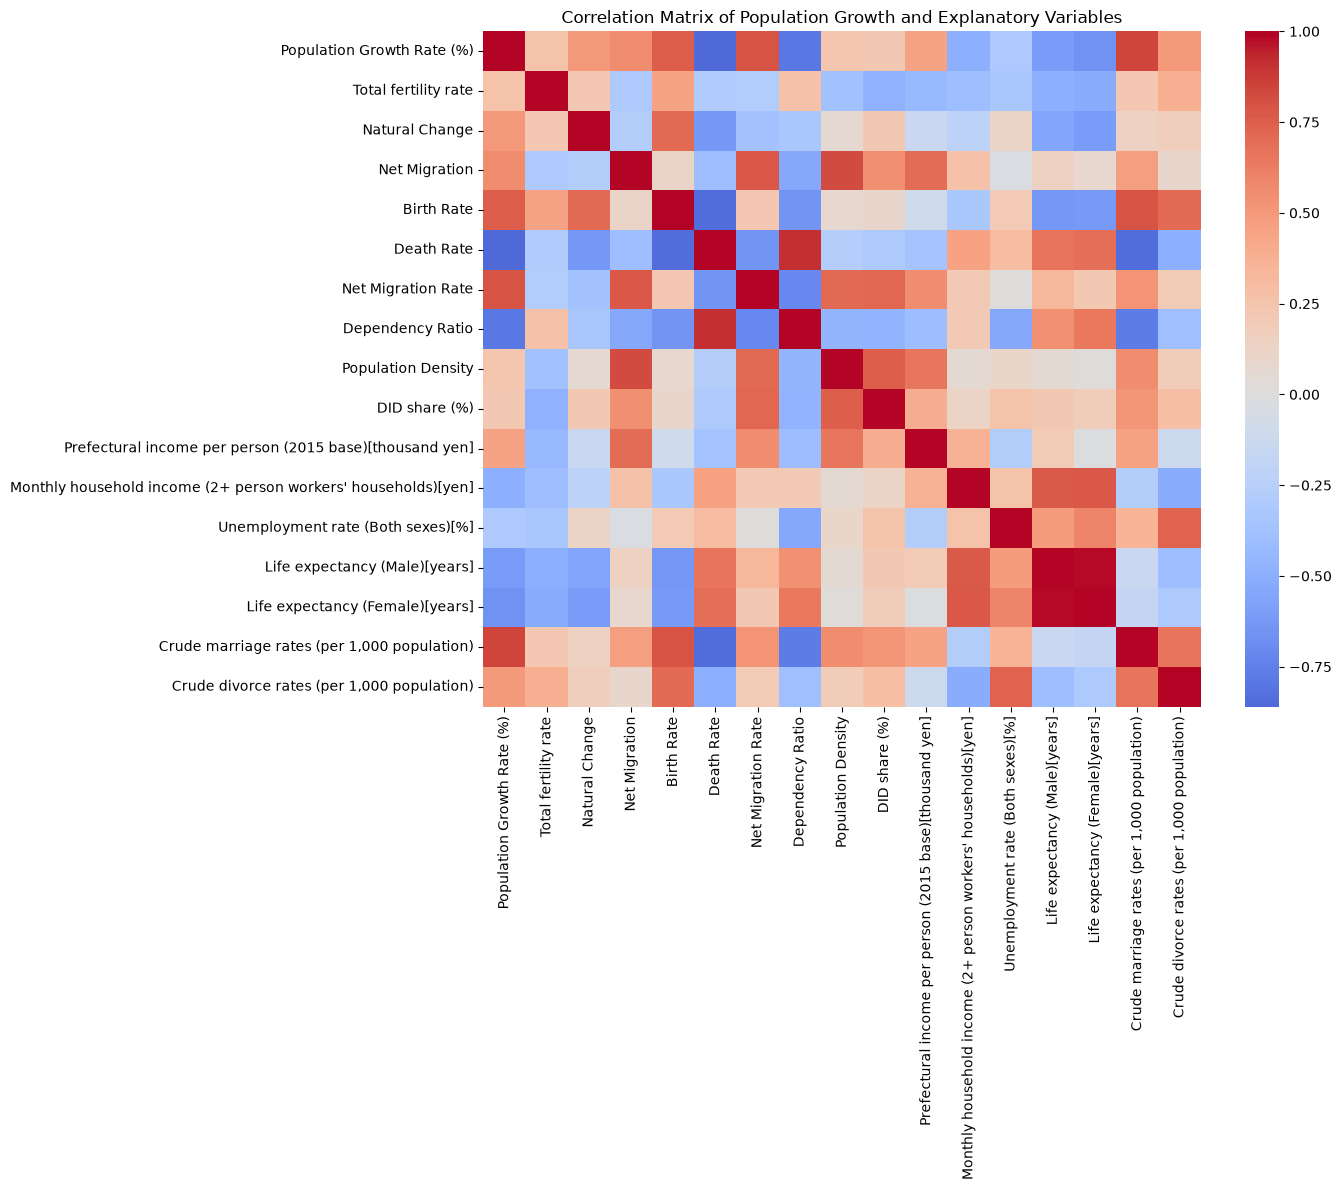

In [50]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(14,12))
sns.heatmap(corr,cmap="coolwarm",center=0,annot=False)
plt.title("Correlation Matrix of Population Growth and Explanatory Variables")
plt.tight_layout()
plt.show()

In [51]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd
vif_data=regional_df[predictors].dropna()
vif=pd.DataFrame()
vif["Variable"]=vif_data.columns
vif["VIF"]=[variance_inflation_factor(vif_data.values,i)for i in range(vif_data.shape[1])]
vif.sort_values("VIF",ascending=False)


,Variable,VIF
4,Death Rate,38.111780
3,Birth Rate,34.690691
6,Dependency Ratio,30.295769
14,"Crude marriage rates (per 1,000 population)",22.933617
0,Total fertility rate,19.849424
12,Life expectancy (Male)[years],11.404321
8,DID share (%),7.646829
15,"Crude divorce rates (per 1,000 population)",7.581788
5,Net Migration Rate,7.307792
2,Net Migration,7.262610


In [52]:
analysis_df = regional_df.copy()
analysis_df=analysis_df.sort_values(["Region Code","Time"]).reset_index(drop=True)

In [53]:
analysis_df[["Population Growth Rate (%)","Population Decline"]].describe()

,Population Growth Rate (%),Population Decline
count,2350.000000,2350.000000
mean,-0.003055,0.511064
std,0.660019,0.499984
min,-2.112017,0.000000
25%,-0.449255,0.000000
50%,-0.035258,1.000000
75%,0.421479,1.000000
max,2.958928,1.000000


In [54]:
analysis_df["Population Decline"].value_counts(dropna=False)

Population Decline
1.0    1201
0.0    1149
NaN      47
Name: count, dtype: int64

In [55]:
analysis_df["Life expectancy"]=(analysis_df["Life expectancy (Male)[years]"]+analysis_df["Life expectancy (Female)[years]"])/2
lag_vars = [
    "Total fertility rate",
    "Net Migration Rate",
    "Dependency Ratio",
    "Population Density",
    "DID share (%)",
    "Prefectural income per person (2015 base)[thousand yen]",
    "Monthly household income (2+ person workers' households)[yen]",
    "Unemployment rate (Both sexes)[%]",
    "Life expectancy",
    "Crude marriage rates (per 1,000 population)",
    "Crude divorce rates (per 1,000 population)"
]


for var in lag_vars:
    analysis_df[f"{var} (lag 1)"]=(analysis_df.groupby("Region Code")[var].shift(1))

analysis_df[
    [
        "Region",
        "Time",
        "Total fertility rate",
        "Total fertility rate (lag 1)",
        "Net Migration Rate",
        "Net Migration Rate (lag 1)"
    ]
].tail(20)

,Region,Time,Total fertility rate,Total fertility rate (lag 1),Net Migration Rate,Net Migration Rate (lag 1)
2377,Okinawa-ken,2006,1.74,1.72,NaN,NaN
2378,Okinawa-ken,2007,1.75,1.74,NaN,NaN
2379,Okinawa-ken,2008,1.78,1.75,NaN,NaN
2380,Okinawa-ken,2009,1.79,1.78,NaN,NaN
2381,Okinawa-ken,2010,1.87,1.79,NaN,NaN
2382,Okinawa-ken,2011,1.86,1.87,NaN,NaN
2383,Okinawa-ken,2012,1.90,1.86,NaN,NaN
2384,Okinawa-ken,2013,1.94,1.90,NaN,NaN
2385,Okinawa-ken,2014,1.86,1.94,-0.174614,NaN
2386,Okinawa-ken,2015,1.96,1.86,-0.064176,-0.174614


In [56]:
lagged_vars=[f"{var} (lag 1)" for var in lag_vars]
analysis_df[lagged_vars].isna().sum()

Total fertility rate (lag 1)                                              517
Net Migration Rate (lag 1)                                               1880
Dependency Ratio (lag 1)                                                 1457
Population Density (lag 1)                                                 47
DID share (%) (lag 1)                                                    1927
Prefectural income per person (2015 base)[thousand yen] (lag 1)          1927
Monthly household income (2+ person workers' households)[yen] (lag 1)      47
Unemployment rate (Both sexes)[%] (lag 1)                                1927
Life expectancy (lag 1)                                                  1927
Crude marriage rates (per 1,000 population) (lag 1)                      1927
Crude divorce rates (per 1,000 population) (lag 1)                       1927
dtype: int64

In [57]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd
vif_data=analysis_df[lagged_vars].dropna()
vif_lagged=pd.DataFrame()
vif_lagged["Variable"]=vif_data.columns
vif_lagged["VIF"]=[variance_inflation_factor(vif_data.values,i)for i in range(vif_data.shape[1])]
vif_lagged.sort_values("VIF",ascending=False)

,Variable,VIF
9,"Crude marriage rates (per 1,000 population) (l...",15.442966
10,"Crude divorce rates (per 1,000 population) (la...",6.120026
2,Dependency Ratio (lag 1),5.915415
0,Total fertility rate (lag 1),5.109043
4,DID share (%) (lag 1),4.853092
5,Prefectural income per person (2015 base)[thou...,4.574231
7,Unemployment rate (Both sexes)[%] (lag 1),4.086598
1,Net Migration Rate (lag 1),3.750334
3,Population Density (lag 1),3.741057
6,Monthly household income (2+ person workers' h...,2.580548


In [60]:
model1_vars = [
    "Population Growth Rate (%)",
    "Total fertility rate (lag 1)",
    "Net Migration Rate (lag 1)",
    "Dependency Ratio (lag 1)",
    "Region Code",
    "Time"
]
model1_df=analysis_df[model1_vars].dropna().copy().set_index(["Region Code","Time"])
model1_df.shape
model1_df.isna().sum()
model1_df
print(model1_df.columns.tolist())
print(model1_df.index.names)


['Population Growth Rate (%)', 'Total fertility rate (lag 1)', 'Net Migration Rate (lag 1)', 'Dependency Ratio (lag 1)']
['Region Code', 'Time']


In [61]:
from linearmodels.panel import PanelOLS
model1=PanelOLS.from_formula(
    formula="Q('Population Growth Rate (%)') ~ Q('Total fertility rate (lag 1)') + Q('Net Migration Rate (lag 1)') + Q('Dependency Ratio (lag 1)') + EntityEffects + TimeEffects",
    data=model1_df)
results1=model1.fit(cov_type="clustered",cluster_entity=True)
print(results1)

                                 PanelOLS Estimation Summary                                 
Dep. Variable:     Q('Population Growth Rate (%)')   R-squared:                        0.1330
Estimator:                                PanelOLS   R-squared (Between):             -0.6547
No. Observations:                              517   R-squared (Within):               0.4225
Date:                             Tue, Oct 13 2026   R-squared (Overall):             -0.5550
Time:                                     23:12:09   Log-likelihood                    365.60
Cov. Estimator:                          Clustered                                           
                                                     F-statistic:                      23.372
Entities:                                       47   P-value                           0.0000
Avg Obs:                                    11.000   Distribution:                   F(3,457)
Min Obs:                                    11.000          

In [62]:
analysis_df["Japanese Net Migration"] = (
    analysis_df["Number of in-migrants (Japanese)【person】"]
    - analysis_df["Number of out-migrants (Japanese)【person】"]
)
analysis_df["Japanese Net Migration Rate"] = analysis_df["Japanese Net Migration"] / analysis_df[pop] * 1000
analysis_df["Japanese Net Migration Rate (lag 1)"] = analysis_df.groupby("Region Code")["Japanese Net Migration Rate"].shift(1)
model1_long_vars = [
    "Population Growth Rate (%)",
    "Total fertility rate (lag 1)",
    "Japanese Net Migration Rate (lag 1)",
    "Dependency Ratio (lag 1)",
    "Region Code",
    "Time"
]
model1_long_df = analysis_df[model1_long_vars].dropna().copy()

model1_long_df=model1_long_df.set_index(["Region Code","Time"])
model1_long=PanelOLS.from_formula(formula="Q('Population Growth Rate (%)') ~ Q('Total fertility rate (lag 1)') + Q('Japanese Net Migration Rate (lag 1)') + Q('Dependency Ratio (lag 1)') + EntityEffects + TimeEffects",data=model1_long_df)
results1_long=model1_long.fit(cov_type="clustered",cluster_entity=True)

print(results1_long)


                                 PanelOLS Estimation Summary                                 
Dep. Variable:     Q('Population Growth Rate (%)')   R-squared:                        0.2456
Estimator:                                PanelOLS   R-squared (Between):              0.8113
No. Observations:                              940   R-squared (Within):               0.6028
Date:                             Tue, Oct 13 2026   R-squared (Overall):              0.7800
Time:                                     23:12:15   Log-likelihood                    638.19
Cov. Estimator:                          Clustered                                           
                                                     F-statistic:                      94.533
Entities:                                       47   P-value                           0.0000
Avg Obs:                                    20.000   Distribution:                   F(3,871)
Min Obs:                                    20.000          

In [63]:
model1_extended_vars=[
    'Population Growth Rate (%)',
    'Total fertility rate (lag 1)',
    'Japanese Net Migration Rate (lag 1)',
    'Region Code',
    'Time',
]
model1_extended_df=analysis_df[model1_extended_vars].dropna().copy()
model1_extended_df=model1_extended_df.set_index(["Region Code","Time"])
model1_extended=PanelOLS.from_formula(formula="Q('Population Growth Rate (%)') ~ Q('Total fertility rate (lag 1)') + Q('Japanese Net Migration Rate (lag 1)') + EntityEffects + TimeEffects",data=model1_extended_df)
results1_extended=model1_extended.fit(cov_type="clustered",cluster_entity=True)
print(results1_extended)

                                 PanelOLS Estimation Summary                                 
Dep. Variable:     Q('Population Growth Rate (%)')   R-squared:                        0.5799
Estimator:                                PanelOLS   R-squared (Between):             -12.979
No. Observations:                             1880   R-squared (Within):               0.5177
Date:                             Tue, Oct 13 2026   R-squared (Overall):             -6.0979
Time:                                     23:12:20   Log-likelihood                    1093.2
Cov. Estimator:                          Clustered                                           
                                                     F-statistic:                      1236.6
Entities:                                       47   P-value                           0.0000
Avg Obs:                                    40.000   Distribution:                  F(2,1792)
Min Obs:                                    40.000          

In [71]:
economic_vars = [
    "Prefectural income per person (2015 base)[thousand yen]",
    "Monthly household income (2+ person workers' households)[yen]",
    "Unemployment rate (Both sexes)[%]",
    
]
for var in economic_vars:
    analysis_df[f'{var} (lag 1)']=analysis_df.groupby("Region Code")[var].shift(1)

In [92]:

analysis_df["Household Income (lag 1)"] = analysis_df[
    "Monthly household income (2+ person workers' households)[yen] (lag 1)"
]
model2_vars = [
    "Population Growth Rate (%)",
    "Total fertility rate (lag 1)",
    "Japanese Net Migration Rate (lag 1)",
    "Dependency Ratio (lag 1)",
    "Prefectural income per person (2015 base)[thousand yen] (lag 1)",
    "Household Income (lag 1)",
    
    "Region Code",
    "Time"
]


model2_df = analysis_df[model2_vars].dropna().copy()

# Exclude the national aggregate
model2_df = model2_df[model2_df["Region Code"] != 0]

# Print diagnostics BEFORE setting the index
print("Shape:", model2_df.shape)
print("Years:", model2_df["Time"].min(), "to", model2_df["Time"].max())
print("Number of years:", model2_df["Time"].nunique())
print("Prefectures:", model2_df["Region Code"].nunique())

# Set panel index
model2_df = model2_df.set_index(["Region Code", "Time"]).sort_index()


Shape: (470, 8)
Years: 2013 to 2022
Number of years: 10
Prefectures: 47


In [94]:
from linearmodels.panel import PanelOLS

model2 = PanelOLS.from_formula(
    "Q('Population Growth Rate (%)') ~ "
    "Q('Total fertility rate (lag 1)') + "
    "Q('Japanese Net Migration Rate (lag 1)') + "
    "Q('Dependency Ratio (lag 1)') + "
    "Q('Prefectural income per person (2015 base)[thousand yen] (lag 1)') + "
    "Q('Household Income (lag 1)') + "
    
    "EntityEffects + TimeEffects",
    data=model2_df
)

results2 = model2.fit(
    cov_type="clustered",
    cluster_entity=True
)

print(results2)



                                 PanelOLS Estimation Summary                                 
Dep. Variable:     Q('Population Growth Rate (%)')   R-squared:                        0.3083
Estimator:                                PanelOLS   R-squared (Between):             -12.325
No. Observations:                              470   R-squared (Within):              -0.0089
Date:                             Tue, Oct 13 2026   R-squared (Overall):             -11.616
Time:                                     23:25:00   Log-likelihood                    524.86
Cov. Estimator:                          Clustered                                           
                                                     F-statistic:                      36.453
Entities:                                       47   P-value                           0.0000
Avg Obs:                                   10.0000   Distribution:                   F(5,409)
Min Obs:                                   10.0000          

In [96]:

from linearmodels.panel import PanelOLS

# Use exactly the same observations as Model 2
model1_common = model2_df[
    [
        "Population Growth Rate (%)",
        "Total fertility rate (lag 1)",
        "Japanese Net Migration Rate (lag 1)",
        "Dependency Ratio (lag 1)"
    ]
].copy()

model1_common = model1_common.dropna()

model1_same_sample = PanelOLS.from_formula(
    "Q('Population Growth Rate (%)') ~ "
    "Q('Total fertility rate (lag 1)') + "
    "Q('Japanese Net Migration Rate (lag 1)') + "
    "Q('Dependency Ratio (lag 1)') + "
    "EntityEffects + TimeEffects",
    data=model1_common
)

results1_same_sample = model1_same_sample.fit(
    cov_type="clustered",
    cluster_entity=True
)

print(results1_same_sample)
print(
    results2.wald_test(
        formula=[
            "Q('Prefectural income per person (2015 base)[thousand yen] (lag 1)') = 0",
            "Q('Household Income (lag 1)') = 0"
        ]
    )
)


                                 PanelOLS Estimation Summary                                 
Dep. Variable:     Q('Population Growth Rate (%)')   R-squared:                        0.2888
Estimator:                                PanelOLS   R-squared (Between):             -9.8415
No. Observations:                              470   R-squared (Within):              -0.0148
Date:                             Tue, Oct 13 2026   R-squared (Overall):             -9.2759
Time:                                     23:38:49   Log-likelihood                    518.35
Cov. Estimator:                          Clustered                                           
                                                     F-statistic:                      55.645
Entities:                                       47   P-value                           0.0000
Avg Obs:                                   10.0000   Distribution:                   F(3,411)
Min Obs:                                   10.0000          

In [97]:
print("Model 1 observations:", results1_same_sample.nobs)
print("Model 1 within R²:", results1_same_sample.rsquared_within)

print("Model 2 observations:", results2.nobs)
print("Model 2 within R²:", results2.rsquared_within)

print("\nPanel index names:", model1_common.index.names)
print("Duplicate prefecture-years:", model1_common.index.duplicated().sum())

print("\nPopulation growth summary:")
print(model1_common["Population Growth Rate (%)"].describe())

Model 1 observations: 470
Model 1 within R²: -0.014750524709574941
Model 2 observations: 470
Model 2 within R²: -0.008867770390979635

Panel index names: ['Region Code', 'Time']
Duplicate prefecture-years: 0

Population growth summary:
count    470.000000
mean      -0.505220
std        0.438557
min       -1.587302
25%       -0.791314
50%       -0.549614
75%       -0.260646
max        0.967269
Name: Population Growth Rate (%), dtype: float64


In [98]:
import numpy as np
import pandas as pd
for name,result in (
    ("Model 1", results1_same_sample),
    ("Model 2", results2)
):
    print(f"\n{name} summary:")
    print(result.summary)
    print("Within R²:", result.rsquared_within)
    print("Overall R²:", result.rsquared_overall)
    print("Model R²:", result.rsquared)
    fitted=result.fitted_values.iloc[:,0]
    residuals=result.resids
    print("Fitted values summary:")
    print(fitted.describe())
    print("Residuals summary:")
    print(residuals.describe())
    print("Residuals skewness:", residuals.skew())
    print("Residual standard deviation:", residuals.std())
    


Model 1 summary:
                                 PanelOLS Estimation Summary                                 
Dep. Variable:     Q('Population Growth Rate (%)')   R-squared:                        0.2888
Estimator:                                PanelOLS   R-squared (Between):             -9.8415
No. Observations:                              470   R-squared (Within):              -0.0148
Date:                             Tue, Oct 13 2026   R-squared (Overall):             -9.2759
Time:                                     23:38:49   Log-likelihood                    518.35
Cov. Estimator:                          Clustered                                           
                                                     F-statistic:                      55.645
Entities:                                       47   P-value                           0.0000
Avg Obs:                                   10.0000   Distribution:                   F(3,411)
Min Obs:                                  

In [102]:

import pandas as pd
import numpy as np

actual = model1_common["Population Growth Rate (%)"]
fitted = results1_same_sample.fitted_values.iloc[:, 0]
resid = results1_same_sample.resids

print("Actual mean:", actual.mean())
print("Fitted mean:", fitted.mean())
print("Residual mean:", resid.mean())

print("\nActual sample:")
print(actual.head(10))

print("\nFitted values:")
print(fitted.head(10))

print("\nResiduals:")
print(resid.head(10))

# Check whether the returned fitted values + residuals
# reconstruct the original dependent variable
check = pd.concat(
    [
        actual.rename("actual"),
        fitted.rename("fitted"),
        resid.rename("residual")
    ],
    axis=1
).dropna()

print("\nCorrelation, actual vs fitted:", check["actual"].corr(check["fitted"]))
print(
    "RMSE using returned fitted values:",
    np.sqrt(np.mean((check["actual"] - check["fitted"]) ** 2))
)
print(
    "Max reconstruction error, actual - fitted - residual:",
    (check["actual"] - check["fitted"] - check["residual"]).abs().max()
)


Actual mean: -0.5052201066536263
Fitted mean: 1.5984864836762103
Residual mean: -2.7165031453594255e-17

Actual sample:
Region Code  Time
1000         2013   -0.494053
             2014   -0.514895
             2015   -0.522495
             2016   -0.496736
             2017   -0.560224
             2018   -0.600939
             2019   -0.642358
             2020   -0.653851
             2021   -0.796499
             2022   -0.829635
Name: Population Growth Rate (%), dtype: float64

Fitted values:
Region Code  Time
1000         2013    1.368341
             2014    1.385492
             2015    1.394500
             2016    1.445747
             2017    1.475835
             2018    1.496634
             2019    1.478702
             2020    1.469534
             2021    1.535956
             2022    1.531971
Name: fitted_values, dtype: float64

Residuals:
Region Code  Time
1000         2013    0.034630
             2014    0.038786
             2015    0.049252
             2016   -0.

In [100]:

import numpy as np
import pandas as pd

result = results1_same_sample
actual = model1_common["Population Growth Rate (%)"]

fitted = result.fitted_values.iloc[:, 0]
effects = result.estimated_effects.iloc[:, 0]
residuals = result.resids

check = pd.concat(
    [
        actual.rename("actual"),
        fitted.rename("fitted_component"),
        effects.rename("estimated_effects"),
        residuals.rename("idiosyncratic_residual")
    ],
    axis=1
).dropna()

check["reconstructed"] = (
    check["fitted_component"]
    + check["estimated_effects"]
    + check["idiosyncratic_residual"]
)

print(check.head(10))

print(
    "\nMaximum reconstruction error:",
    (check["actual"] - check["reconstructed"]).abs().max()
)

print(
    "RMSE of full fitted values:",
    np.sqrt(
        np.mean(
            (check["actual"] - check["fitted_component"]
             - check["estimated_effects"]) ** 2
        )
    )
)


                    actual  fitted_component  estimated_effects  \
Region Code Time                                                  
1000        2013 -0.494053          1.368341          -1.897024   
            2014 -0.514895          1.385492          -1.939173   
            2015 -0.522495          1.394500          -1.966247   
            2016 -0.496736          1.445747          -1.940897   
            2017 -0.560224          1.475835          -2.013810   
            2018 -0.600939          1.496634          -2.067967   
            2019 -0.642358          1.478702          -2.100839   
            2020 -0.653851          1.469534          -2.159061   
            2021 -0.796499          1.535956          -2.303224   
            2022 -0.829635          1.531971          -2.306155   

                  idiosyncratic_residual  reconstructed  
Region Code Time                                         
1000        2013                0.034630      -0.494053  
            2014     

In [104]:
actual = model1_common["Population Growth Rate (%)"]

full_fitted = (
    results1_same_sample.fitted_values.iloc[:, 0]
    + results1_same_sample.estimated_effects.iloc[:, 0]
)

rmse_model = ((actual - full_fitted) ** 2).mean() ** 0.5

prefecture_mean = actual.groupby(level="Region Code").transform("mean")
rmse_prefecture_mean = ((actual - prefecture_mean) ** 2).mean() ** 0.5

print("Full-model in-sample RMSE:", rmse_model)
print("Prefecture-mean benchmark RMSE:", rmse_prefecture_mean)
print("RMSE improvement:", rmse_prefecture_mean - rmse_model)

Full-model in-sample RMSE: 0.08031377866328099
Prefecture-mean benchmark RMSE: 0.16043039219356486
RMSE improvement: 0.08011661353028388


In [106]:
from linearmodels.panel import PanelOLS
print([name for name in dir(results1_same_sample) if any(term in name.lower() for term in ["fitted","resid","effect","wald",'test',])])

['_df_resid', '_effects', '_entity_effect', '_fitted', '_other_effect', '_r2_ex_effects', '_resids', '_residual_ss', '_sigma2_effects', '_time_effect', '_wresids', 'df_resid', 'estimated_effects', 'fitted_values', 'included_effects', 'resid_ss', 'resids', 'wald_test', 'wresids']


In [107]:

import pandas as pd
import numpy as np
from scipy.stats import skew

# Inspect the residuals from Model 1
residuals = results1_same_sample.resids

print("Number of residuals:", residuals.notna().sum())
print("Mean residual:", residuals.mean())
print("Residual standard deviation:", residuals.std())
print("Minimum residual:", residuals.min())
print("Maximum residual:", residuals.max())
print("Residual skewness:", skew(residuals.dropna()))


Number of residuals: 470
Mean residual: -2.7165031453594255e-17
Residual standard deviation: 0.08039935543626694
Minimum residual: -0.45744205730982673
Maximum residual: 0.2708071899887634
Residual skewness: -0.21622532586335041


In [108]:

import numpy as np
import pandas as pd
from scipy.stats import norm

# Get Model 1 residuals and arrange them as prefectures × years
resid = results1_same_sample.resids.rename("residual").reset_index()

# Use the panel's actual index column names
print("Index columns:", resid.columns.tolist())


Index columns: ['Region Code', 'Time', 'residual']


In [109]:

import numpy as np
import pandas as pd
from scipy.stats import norm

# Arrange residuals: rows = years, columns = prefectures
residual_matrix = resid.pivot(
    index="Time",
    columns="Region Code",
    values="residual"
)

# Keep only prefectures with complete residual data
residual_matrix = residual_matrix.dropna(axis=1)

T, N = residual_matrix.shape

# Correlation between residuals of every pair of prefectures
correlation_matrix = residual_matrix.corr()

# Extract correlations above the diagonal to avoid double-counting
pairwise_correlations = correlation_matrix.to_numpy()[
    np.triu_indices(N, k=1)
]

# Pesaran CD statistic
CD = np.sqrt(2 * T / (N * (N - 1))) * pairwise_correlations.sum()

# Two-sided p-value under the standard normal approximation
p_value = 2 * norm.sf(abs(CD))

print("Number of years:", T)
print("Number of prefectures:", N)
print("Pesaran CD statistic:", CD)
print("p-value:", p_value)

if p_value < 0.05:
    print("Result: Evidence of cross-sectional dependence at the 5% level.")
else:
    print("Result: Insufficient evidence of cross-sectional dependence at the 5% level.")


Number of years: 10
Number of prefectures: 47
Pesaran CD statistic: -2.1420372949563298
p-value: 0.032190481034061455
Result: Evidence of cross-sectional dependence at the 5% level.


In [110]:

# Re-estimate the covariance matrix using Driscoll–Kraay SEs
results1_dk = model1_same_sample.fit(
    cov_type="kernel",
    kernel="bartlett",
    bandwidth=2
)

print(results1_dk.summary)


                                 PanelOLS Estimation Summary                                 
Dep. Variable:     Q('Population Growth Rate (%)')   R-squared:                        0.2888
Estimator:                                PanelOLS   R-squared (Between):             -9.8415
No. Observations:                              470   R-squared (Within):              -0.0148
Date:                             Wed, Oct 14 2026   R-squared (Overall):             -9.2759
Time:                                     00:41:33   Log-likelihood                    518.35
Cov. Estimator:                     Driscoll-Kraay                                           
                                                     F-statistic:                      55.645
Entities:                                       47   P-value                           0.0000
Avg Obs:                                   10.0000   Distribution:                   F(3,411)
Min Obs:                                   10.0000          

In [111]:

for bw in [1, 2, 3]:
    result = model1_same_sample.fit(
        cov_type="kernel",
        kernel="bartlett",
        bandwidth=bw
    )

    print(f"\nBandwidth = {bw}")
    print(
        result.summary.tables[1]
    )



Bandwidth = 1
                                            Parameter Estimates                                             
                                          Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
------------------------------------------------------------------------------------------------------------
Q('Total fertility rate (lag 1)')            0.6799     0.1974     3.4448     0.0006      0.2919      1.0678
Q('Japanese Net Migration Rate (lag 1)')     0.0706     0.0059     11.995     0.0000      0.0591      0.0822
Q('Dependency Ratio (lag 1)')                0.0099     0.0084     1.1694     0.2429     -0.0067      0.0265

Bandwidth = 2
                                            Parameter Estimates                                             
                                          Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
--------------------------------------------------------------------------------------------------

In [112]:

import pandas as pd
import numpy as np
import statsmodels.api as sm
from scipy.stats import t

# Retrieve Model 1 residuals
resid_df = (
    results1_same_sample.resids
    .rename("residual")
    .reset_index()
    .sort_values(["Region Code", "Time"])
)

# First-difference residuals within each prefecture
resid_df["diff_resid"] = (
    resid_df.groupby("Region Code")["residual"].diff()
)

# Lag the first-differenced residuals within each prefecture
resid_df["lag_diff_resid"] = (
    resid_df.groupby("Region Code")["diff_resid"].shift(1)
)

test_df = resid_df.dropna(
    subset=["diff_resid", "lag_diff_resid"]
)

# Regress current differences on lagged differences
X = sm.add_constant(test_df["lag_diff_resid"])
ols_result = sm.OLS(test_df["diff_resid"], X).fit()

# Test the null that the slope equals -0.5
slope = ols_result.params["lag_diff_resid"]
se = ols_result.bse["lag_diff_resid"]
test_stat = (slope - (-0.5)) / se
p_value = 2 * t.sf(abs(test_stat), ols_result.df_resid)

print("Observations used:", len(test_df))
print("Estimated slope:", slope)
print("Test statistic:", test_stat)
print("p-value:", p_value)


Observations used: 376
Estimated slope: -0.3456533408478505
Test statistic: 2.8369169786877126
p-value: 0.004803140540156586


In [119]:

import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.stats import f

# Use residuals from your existing two-way fixed-effects model
resid_df = (
    results1_same_sample.resids
    .rename("residual")
    .reset_index()
    .sort_values(["Region Code", "Time"])
    .copy()
)

# First differences within each prefecture
resid_df["diff_resid"] = (
    resid_df.groupby("Region Code")["residual"].diff()
)

# Lag the first differences within each prefecture
resid_df["lag_diff_resid"] = (
    resid_df.groupby("Region Code")["diff_resid"].shift(1)
)

test_df = resid_df.dropna(
    subset=["diff_resid", "lag_diff_resid"]
).copy()

# Auxiliary regression, without an intercept
aux = sm.OLS(
    test_df["diff_resid"],
    test_df[["lag_diff_resid"]]
).fit(
    cov_type="cluster",
    cov_kwds={"groups": test_df["Region Code"]}
)

# Wooldridge null restriction: coefficient = -0.5
beta = aux.params["lag_diff_resid"]
se = aux.bse["lag_diff_resid"]
t_stat = (beta + 0.5) / se

# Use the number of prefectures minus one for the F reference df
N = test_df["Region Code"].nunique()
F_stat = t_stat**2
p_value = f.sf(F_stat, 1, N - 1)

print("Prefectures:", N)
print("Observations used:", len(test_df))
print("Estimated coefficient:", beta)
print("Clustered standard error:", se)
print("Wooldridge-style F statistic:", F_stat)
print("p-value:", p_value)

if p_value < 0.05:
    print("Reject H0: evidence against no first-order serial correlation.")
else:
    print("Fail to reject H0: insufficient evidence against the null.")


Prefectures: 47
Observations used: 376
Estimated coefficient: -0.34565334084785054
Clustered standard error: 0.05703416641722561
Wooldridge-style F statistic: 7.323594167820168
p-value: 0.009515759611005514
Reject H0: evidence against no first-order serial correlation.


In [121]:

# ============================================================
# FULL-SAMPLE MODEL A — ADD-ON TO YOUR EXISTING ANALYSIS
# Reuses analysis_df and your already-created lagged variables.
# Does not reload the CSV or recalculate initial variables.
# ============================================================

from linearmodels.panel import PanelOLS
from scipy import stats
from scipy.stats import f
import statsmodels.api as sm
import numpy as np
import pandas as pd

DV = "Population Growth Rate (%)"
X_COLS = [
    "Total fertility rate (lag 1)",
    "Japanese Net Migration Rate (lag 1)",
    "Dependency Ratio (lag 1)"
]

# ------------------------------------------------------------
# 1. Build the maximum complete sample for Model A only
# ------------------------------------------------------------

modelA_full_df = analysis_df[
    ["Region Code", "Time", DV] + X_COLS
].copy()

# Exclude national aggregate; retain all available prefecture-years.
modelA_full_df = modelA_full_df[
    modelA_full_df["Region Code"] != 0
].dropna(subset=[DV] + X_COLS)

modelA_full_df = (
    modelA_full_df
    .sort_values(["Region Code", "Time"])
    .set_index(["Region Code", "Time"])
)

print("\n===== FULL-SAMPLE MODEL A =====")
print("Observations:", len(modelA_full_df))
print("Prefectures:", modelA_full_df.index.get_level_values(0).nunique())
print(
    "Years:",
    modelA_full_df.index.get_level_values(1).min(),
    "to",
    modelA_full_df.index.get_level_values(1).max()
)

# ------------------------------------------------------------
# 2. Two-way fixed effects; cluster by prefecture
# ------------------------------------------------------------

formula_A_full = (
    f'Q("{DV}") ~ '
    + " + ".join(f'Q("{c}")' for c in X_COLS)
    + " + EntityEffects + TimeEffects"
)

modelA_full = PanelOLS.from_formula(
    formula_A_full,
    data=modelA_full_df,
    drop_absorbed=True
)

resultsA_full = modelA_full.fit(
    cov_type="clustered",
    cluster_entity=True
)

print("\n===== MODEL A: PREFECTURE-CLUSTERED SE =====")
print(resultsA_full.summary)

# Keep a compact table for later comparison/reporting.
table_A_full = pd.DataFrame({
    "Coefficient": resultsA_full.params,
    "Clustered SE": resultsA_full.std_errors,
    "t": resultsA_full.tstats,
    "p": resultsA_full.pvalues,
    "CI lower": resultsA_full.conf_int().iloc[:, 0],
    "CI upper": resultsA_full.conf_int().iloc[:, 1]
})

print("\n===== COEFFICIENT TABLE =====")
print(table_A_full.round(6))


# ------------------------------------------------------------
# 3. Driscoll-Kraay standard errors and bandwidth sensitivity
# ------------------------------------------------------------

dk_A_full = {}

for bw in [1, 2, 3]:
    dk_A_full[bw] = modelA_full.fit(
        cov_type="kernel",
        kernel="bartlett",
        bandwidth=bw
    )

dk_comparison_A_full = pd.concat(
    {
        f"Bandwidth {bw}": pd.DataFrame({
            "Coefficient": res.params,
            "SE": res.std_errors,
            "p-value": res.pvalues,
            "CI lower": res.conf_int().iloc[:, 0],
            "CI upper": res.conf_int().iloc[:, 1]
        })
        for bw, res in dk_A_full.items()
    },
    axis=1
)

print("\n===== DRISCOLL-KRAAY SENSITIVITY =====")
print(dk_comparison_A_full.round(6))


# ------------------------------------------------------------
# 4. Residuals and full fitted values
# ------------------------------------------------------------

resid_A = resultsA_full.resids.rename("residual")
fitted_component_A = resultsA_full.fitted_values.iloc[:, 0]
effects_A = resultsA_full.estimated_effects.iloc[:, 0]

diag_A = pd.concat([
    modelA_full_df[DV].rename("actual"),
    fitted_component_A.rename("fitted_component"),
    effects_A.rename("estimated_effects"),
    resid_A
], axis=1).dropna()

diag_A["full_fitted"] = (
    diag_A["fitted_component"] + diag_A["estimated_effects"]
)

diag_A["reconstructed"] = (
    diag_A["full_fitted"] + diag_A["residual"]
)

print("\n===== RESIDUAL DIAGNOSTICS =====")
print(diag_A["residual"].describe())
print("Residual mean:", diag_A["residual"].mean())
print("Residual SD:", diag_A["residual"].std())
print("Residual skewness:", stats.skew(diag_A["residual"]))
print(
    "Maximum reconstruction error:",
    (diag_A["actual"] - diag_A["reconstructed"]).abs().max()
)

jb_A = stats.jarque_bera(diag_A["residual"])
print("Jarque-Bera statistic:", jb_A.statistic)
print("Jarque-Bera p-value:", jb_A.pvalue)


# ------------------------------------------------------------
# 5. In-sample RMSE vs prefecture-mean benchmark
# ------------------------------------------------------------

rmse_A = np.sqrt(
    np.mean((diag_A["actual"] - diag_A["full_fitted"]) ** 2)
)

prefecture_means_A = (
    diag_A["actual"]
    .groupby(level="Region Code")
    .transform("mean")
)

rmse_benchmark_A = np.sqrt(
    np.mean((diag_A["actual"] - prefecture_means_A) ** 2)
)

print("\n===== IN-SAMPLE FIT =====")
print("Model RMSE:", rmse_A)
print("Prefecture-mean benchmark RMSE:", rmse_benchmark_A)
print(
    "RMSE reduction (%):",
    100 * (1 - rmse_A / rmse_benchmark_A)
    if rmse_benchmark_A else np.nan
)


# ------------------------------------------------------------
# 6. Pesaran-style cross-sectional dependence screen
# ------------------------------------------------------------

resid_long_A = (
    resid_A.reset_index()
    .rename(columns={"Region Code": "Region Code", "Time": "Time"})
)

resid_matrix_A = resid_long_A.pivot(
    index="Time",
    columns="Region Code",
    values="residual"
)

# The conventional calculation below uses a balanced residual matrix.
resid_matrix_A = resid_matrix_A.dropna(axis=0, how="any")
resid_matrix_A = resid_matrix_A.dropna(axis=1, how="any")

T_A, N_A = resid_matrix_A.shape

print("\n===== CROSS-SECTIONAL DEPENDENCE SCREEN =====")
print("Complete years:", T_A)
print("Prefectures:", N_A)

if T_A >= 2 and N_A >= 2:
    corr_A = resid_matrix_A.corr().to_numpy()
    pair_corr_A = corr_A[np.triu_indices(N_A, k=1)]

    cd_A = np.sqrt(
        2 * T_A / (N_A * (N_A - 1))
    ) * pair_corr_A.sum()

    cd_p_A = 2 * stats.norm.sf(abs(cd_A))

    print("CD statistic:", cd_A)
    print("Asymptotic p-value:", cd_p_A)
else:
    print("Insufficient complete data for the CD calculation.")


# ------------------------------------------------------------
# 7. Exploratory residual serial-correlation screen
# Same custom procedure previously explored.
# NOT a definitive formal Wooldridge test.
# ------------------------------------------------------------

serial_A = (
    resid_A.reset_index()
    .sort_values(["Region Code", "Time"])
    .copy()
)

serial_A["diff_resid"] = (
    serial_A.groupby("Region Code")["residual"].diff()
)

serial_A["lag_diff_resid"] = (
    serial_A.groupby("Region Code")["diff_resid"].shift(1)
)

serial_A = serial_A.dropna(
    subset=["diff_resid", "lag_diff_resid"]
)

if len(serial_A):
    aux_A = sm.OLS(
        serial_A["diff_resid"],
        serial_A[["lag_diff_resid"]]
    ).fit(
        cov_type="cluster",
        cov_kwds={"groups": serial_A["Region Code"]}
    )

    beta_A = aux_A.params["lag_diff_resid"]
    se_A = aux_A.bse["lag_diff_resid"]

    t_A = (beta_A + 0.5) / se_A
    F_A = t_A ** 2
    n_entities_A = serial_A["Region Code"].nunique()
    p_serial_A = f.sf(F_A, 1, n_entities_A - 1)

    print("\n===== EXPLORATORY SERIAL SCREEN =====")
    print("Auxiliary coefficient:", beta_A)
    print("Clustered SE:", se_A)
    print("F statistic:", F_A)
    print("Approximate p-value:", p_serial_A)
    print(
        "This custom screen is exploratory, not a validated "
        "formal Wooldridge-test result."
    )


# ------------------------------------------------------------
# 8. Save only the new Model A outputs
# ------------------------------------------------------------

table_A_full.to_csv("modelA_full_sample_coefficients.csv")
dk_comparison_A_full.to_csv("modelA_full_sample_DK_comparison.csv")
diag_A.to_csv("modelA_full_sample_residuals.csv")

print("\nFull-sample Model A diagnostics completed.")



===== FULL-SAMPLE MODEL A =====
Observations: 940
Prefectures: 47
Years: 2006 to 2025

===== MODEL A: PREFECTURE-CLUSTERED SE =====
                                 PanelOLS Estimation Summary                                 
Dep. Variable:     Q('Population Growth Rate (%)')   R-squared:                        0.2456
Estimator:                                PanelOLS   R-squared (Between):              0.8113
No. Observations:                              940   R-squared (Within):               0.6028
Date:                             Wed, Oct 14 2026   R-squared (Overall):              0.7800
Time:                                     01:02:47   Log-likelihood                    638.19
Cov. Estimator:                          Clustered                                           
                                                     F-statistic:                      94.533
Entities:                                       47   P-value                           0.0000
Avg Obs:             

In [122]:

# Identify the most extreme negative residuals in full-sample Model A.
# This inspects existing results; it does not change the model.

outliers_A = diag_A.sort_values("residual").head(15).copy()

print("15 most negative residuals:")
print(
    outliers_A[
        ["actual", "full_fitted", "residual"]
    ].to_string()
)

print("\n15 largest positive residuals:")
print(
    diag_A.sort_values("residual", ascending=False)
    .head(15)[["actual", "full_fitted", "residual"]]
    .to_string()
)

# See whether the most extreme residuals are concentrated
# in particular prefectures or years.
print("\nResiduals by prefecture:")
print(
    diag_A.groupby(level="Region Code")["residual"]
    .agg(["mean", "std", "min", "max", "count"])
    .sort_values("min")
    .head(10)
)

print("\nResiduals by year:")
print(
    diag_A.groupby(level="Time")["residual"]
    .agg(["mean", "std", "min", "max", "count"])
    .to_string()
)


15 most negative residuals:
                    actual  full_fitted  residual
Region Code Time                                 
7000        2011 -2.023790    -0.838641 -1.185149
4000        2011 -0.943929    -0.221097 -0.722832
13000       2021 -0.267619     0.321353 -0.588972
22000       2025 -1.648852    -1.069605 -0.579247
20000       2025 -1.612984    -1.053713 -0.559271
32000       2025 -1.953271    -1.434658 -0.518613
13000       2020  0.289812     0.714572 -0.424759
19000       2025 -1.401770    -1.050236 -0.351533
2000        2025 -2.112017    -1.778236 -0.333781
22000       2010 -0.475628    -0.158169 -0.317459
23000       2010 -0.003792     0.311397 -0.315188
30000       2025 -1.788409    -1.491462 -0.296947
23000       2009  0.162184     0.445961 -0.283777
12000       2012 -0.273444     0.008540 -0.281984
43000       2016 -0.625360    -0.350630 -0.274731

15 largest positive residuals:
                    actual  full_fitted  residual
Region Code Time                        

In [123]:

# Inspect the original Model A variables for the most extreme residuals.
# Uses existing modelA_full_df and diag_A.

predictor_cols = [
    "Total fertility rate (lag 1)",
    "Japanese Net Migration Rate (lag 1)",
    "Dependency Ratio (lag 1)"
]

# Merge the already-existing predictors with the residual diagnostics.
outlier_details_A = (
    modelA_full_df[predictor_cols]
    .join(diag_A[["actual", "full_fitted", "residual"]], how="inner")
)

print("\n===== 15 MOST NEGATIVE RESIDUALS: ORIGINAL VALUES =====")
print(
    outlier_details_A
    .sort_values("residual")
    .head(15)
    .to_string()
)

print("\n===== 15 LARGEST POSITIVE RESIDUALS: ORIGINAL VALUES =====")
print(
    outlier_details_A
    .sort_values("residual", ascending=False)
    .head(15)
    .to_string()
)

# Compare the unusual years with the overall sample.
print("\n===== OUTLIER YEARS VS FULL SAMPLE =====")

for year in [2011, 2020, 2021, 2025]:
    year_data = outlier_details_A[
        outlier_details_A.index.get_level_values("Time") == year
    ]

    if len(year_data):
        print(f"\nYear: {year}")
        print(
            year_data[
                ["actual", "full_fitted", "residual"] + predictor_cols
            ].describe().round(4).to_string()
        )

print("\n===== OVERALL SAMPLE SUMMARY =====")
print(outlier_details_A.describe().round(4).to_string())



===== 15 MOST NEGATIVE RESIDUALS: ORIGINAL VALUES =====
                  Total fertility rate (lag 1)  Japanese Net Migration Rate (lag 1)  Dependency Ratio (lag 1)    actual  full_fitted  residual
Region Code Time                                                                                                                              
7000        2011                          1.52                            -2.834805                 63.132137 -2.023790    -0.838641 -1.185149
4000        2011                          1.30                            -0.236781                 55.124224 -0.943929    -0.221097 -0.722832
13000       2021                          1.12                             2.731713                 51.285930 -0.267619     0.321353 -0.588972
22000       2025                          1.19                            -2.181741                 73.310225 -1.648852    -1.069605 -0.579247
20000       2025                          1.30                            -0.689482  

In [124]:

# Sensitivity analysis: omit one unusual year at a time.
# Keep the full sample and previous results unchanged.

sensitivity_A = {
    "Full sample": resultsA_full.params
}

for year_to_omit in [2011, 2025]:
    reduced_df = modelA_full_df[
        modelA_full_df.index.get_level_values("Time") != year_to_omit
    ].copy()

    reduced_model = PanelOLS.from_formula(
        formula_A_full,
        data=reduced_df,
        drop_absorbed=True
    )

    reduced_results = reduced_model.fit(
        cov_type="clustered",
        cluster_entity=True
    )

    sensitivity_A[f"Without {year_to_omit}"] = reduced_results.params

sensitivity_table_A = pd.DataFrame(sensitivity_A)

print("\n===== MODEL A COEFFICIENT SENSITIVITY =====")
print(sensitivity_table_A.round(6))

print("\n===== CHANGE FROM FULL-SAMPLE ESTIMATES =====")
for label in ["Without 2011", "Without 2025"]:
    change = sensitivity_table_A[label] - sensitivity_table_A["Full sample"]
    print(f"\n{label}:")
    print(change.round(6))



===== MODEL A COEFFICIENT SENSITIVITY =====
                                          Full sample  Without 2011  \
Q('Total fertility rate (lag 1)')            0.441499      0.482632   
Q('Japanese Net Migration Rate (lag 1)')     0.072358      0.072282   
Q('Dependency Ratio (lag 1)')               -0.017874     -0.015947   

                                          Without 2025  
Q('Total fertility rate (lag 1)')             0.391519  
Q('Japanese Net Migration Rate (lag 1)')      0.073429  
Q('Dependency Ratio (lag 1)')                -0.015931  

===== CHANGE FROM FULL-SAMPLE ESTIMATES =====

Without 2011:
Q('Total fertility rate (lag 1)')           0.041134
Q('Japanese Net Migration Rate (lag 1)')   -0.000076
Q('Dependency Ratio (lag 1)')               0.001927
dtype: float64

Without 2025:
Q('Total fertility rate (lag 1)')          -0.049979
Q('Japanese Net Migration Rate (lag 1)')    0.001072
Q('Dependency Ratio (lag 1)')               0.001943
dtype: float64


In [125]:

# Complete the sensitivity analysis with inference statistics.

sensitivity_inference_A = {}

# Full-sample inference
sensitivity_inference_A["Full sample"] = pd.DataFrame({
    "Coefficient": resultsA_full.params,
    "SE": resultsA_full.std_errors,
    "p-value": resultsA_full.pvalues,
    "CI lower": resultsA_full.conf_int().iloc[:, 0],
    "CI upper": resultsA_full.conf_int().iloc[:, 1]
})

for year_to_omit in [2011, 2025]:
    reduced_df = modelA_full_df[
        modelA_full_df.index.get_level_values("Time") != year_to_omit
    ].copy()

    reduced_model = PanelOLS.from_formula(
        formula_A_full,
        data=reduced_df,
        drop_absorbed=True
    )

    reduced_results = reduced_model.fit(
        cov_type="clustered",
        cluster_entity=True
    )

    sensitivity_inference_A[f"Without {year_to_omit}"] = pd.DataFrame({
        "Coefficient": reduced_results.params,
        "SE": reduced_results.std_errors,
        "p-value": reduced_results.pvalues,
        "CI lower": reduced_results.conf_int().iloc[:, 0],
        "CI upper": reduced_results.conf_int().iloc[:, 1]
    })

for label, table in sensitivity_inference_A.items():
    print(f"\n===== {label} =====")
    print(table.round(6).to_string())



===== Full sample =====
                                          Coefficient        SE   p-value  CI lower  CI upper
Q('Total fertility rate (lag 1)')            0.441499  0.129578  0.000686  0.187176  0.695821
Q('Japanese Net Migration Rate (lag 1)')     0.072358  0.007415  0.000000  0.057805  0.086910
Q('Dependency Ratio (lag 1)')               -0.017874  0.002973  0.000000 -0.023710 -0.012038

===== Without 2011 =====
                                          Coefficient        SE   p-value  CI lower  CI upper
Q('Total fertility rate (lag 1)')            0.482632  0.130294  0.000226  0.226885  0.738380
Q('Japanese Net Migration Rate (lag 1)')     0.072282  0.006424  0.000000  0.059673  0.084891
Q('Dependency Ratio (lag 1)')               -0.015947  0.003161  0.000001 -0.022152 -0.009742

===== Without 2025 =====
                                          Coefficient        SE   p-value  CI lower  CI upper
Q('Total fertility rate (lag 1)')            0.391519  0.123877  0.001632  0.

In [126]:

# ============================================================
# FORMAL WOOLDRIDGE AR(1) TEST USING PANELBOX
# Reuses modelA_full_df; does not reload the CSV.
# ============================================================

from panelbox import FixedEffects
from panelbox.validation.serial_correlation.wooldridge_ar import (
    WooldridgeARTest
)

# Make a separate copy and use simple column names for PanelBox.
pb_data = modelA_full_df.reset_index().copy()

pb_data = pb_data.rename(columns={
    "Region Code": "prefecture",
    "Time": "year",
    "Population Growth Rate (%)": "growth",
    "Total fertility rate (lag 1)": "fertility",
    "Japanese Net Migration Rate (lag 1)": "migration",
    "Dependency Ratio (lag 1)": "dependency"
})

# Confirm the sample is identical to the full-sample Model A.
print("Observations:", len(pb_data))
print("Prefectures:", pb_data["prefecture"].nunique())
print("Years:", pb_data["year"].min(), "-", pb_data["year"].max())

# Estimate the same two-way fixed-effects specification.
pb_model_A = FixedEffects(
    formula="growth ~ fertility + migration + dependency",
    data=pb_data,
    entity_col="prefecture",
    time_col="year",
    entity_effects=True,
    time_effects=True
)

pb_results_A = pb_model_A.fit(cov_type="clustered")

print("\n===== PANELBOX TWO-WAY FE MODEL =====")
print(pb_results_A.summary())

print("\n===== COEFFICIENT COMPARISON =====")
print("linearmodels:")
print(resultsA_full.params)

print("\nPanelBox:")
print(pb_results_A.params)

# Run the package's Wooldridge AR(1) test on its own result object.
wooldridge_A = WooldridgeARTest(pb_results_A)
wooldridge_result_A = wooldridge_A.run(alpha=0.05)

print("\n===== WOOLDRIDGE AR(1) TEST =====")
print(wooldridge_result_A.summary())

print("F-statistic:", wooldridge_result_A.statistic)
print("p-value:", wooldridge_result_A.pvalue)
print("Reject null:", wooldridge_result_A.reject_null)
print("Conclusion:", wooldridge_result_A.conclusion)
print("Metadata:", wooldridge_result_A.metadata)


Observations: 940
Prefectures: 47
Years: 2006 - 2025

===== PANELBOX TWO-WAY FE MODEL =====
                  Fixed Effects (Two-Way) Estimation Results                  
Formula: growth ~ fertility + migration + dependency
Model:   Fixed Effects (Two-Way)
------------------------------------------------------------------------------
No. Observations:                 940
No. Entities:                      47
No. Time Periods:                  20
Degrees of Freedom:               870
R-squared:                     0.7931
Adj. R-squared:                0.7767
R-squared (within):            0.7931
R-squared (between):           0.7695
R-squared (overall):           0.7765
Standard Errors:            clustered
F-statistic (FE vs OLS):      -8.7610
F-test p-value:                1.0000
Variable        Coef.        Std.Err.     t        P>|t|    [0.025     0.975]    
------------------------------------------------------------------------------
fertility            0.4415      0.1262   3.498

In [128]:

from panelbox.validation.cross_sectional_dependence.pesaran_cd import (
    PesaranCDTest
)
from panelbox.validation.cross_sectional_dependence.breusch_pagan_lm import (
    BreuschPaganLMTest
)
from panelbox.validation.cross_sectional_dependence.frees import (
    FreesTest
)

# Pesaran CD test
pesaran_A = PesaranCDTest(pb_results_A).run(alpha=0.05)

print("===== PESARAN CD TEST =====")
print(pesaran_A.summary())
print("Statistic:", pesaran_A.statistic)
print("P-value:", pesaran_A.pvalue)
print("Reject H0:", pesaran_A.reject_null)

# Breusch-Pagan LM test
bp_A = BreuschPaganLMTest(pb_results_A).run(alpha=0.05)

print("\n===== BREUSCH-PAGAN LM TEST =====")
print(bp_A.summary())
print("Statistic:", bp_A.statistic)
print("P-value:", bp_A.pvalue)
print("Reject H0:", bp_A.reject_null)

# Frees test
frees_A = FreesTest(pb_results_A).run(alpha=0.05)

print("\n===== FREES TEST =====")
print(frees_A.summary())
print("Statistic:", frees_A.statistic)
print("P-value:", frees_A.pvalue)
print("Reject H0:", frees_A.reject_null)


===== PESARAN CD TEST =====
PESARAN CD TEST FOR CROSS-SECTIONAL DEPENDENCE

H0: No cross-sectional dependence
H1: Cross-sectional dependence present

----------------------------------------------------------------------
Test Statistic                         -2.1412
P-value                                 0.0323
----------------------------------------------------------------------

Conclusion: Reject H0 at 5% level. Cross-sectional dependence present

Additional Information:
  n_entities: 47
  n_time_periods: 20
  n_pairs: 1081
  avg_correlation: -0.0146
  avg_abs_correlation: 0.2892
  max_abs_correlation: 0.8865
  min_correlation: -0.8865
  max_correlation: 0.8760

Statistic: -2.141233607093062
P-value: 0.032255204155752004
Reject H0: True

===== BREUSCH-PAGAN LM TEST =====
BREUSCH-PAGAN LM TEST FOR CROSS-SECTIONAL DEPENDENCE

H0: No cross-sectional dependence (residuals independent across entities)
H1: Cross-sectional dependence present

--------------------------------------------

In [130]:

# ================================================================
# MODEL 2: COMPLETE ECONOMETRIC ANALYSIS
# Japanese Prefectural Population Growth Study
#
# Model: Two-way fixed effects
# Sample: Expected 470 observations, 47 prefectures, 2013-2022
#
# Requires existing model2_df with:
#   - MultiIndex: Region Code, Time
#   - Population Growth Rate (%)
#   - Total fertility rate (lag 1)
#   - Japanese Net Migration Rate (lag 1)
#   - Dependency Ratio (lag 1)
#   - Prefectural income per person (2015 base)[thousand yen] (lag 1)
#   - Household Income (lag 1)
#
# Does not reload the CSV.
# ================================================================


# ================================================================
# 0. IMPORTS AND VARIABLE DEFINITIONS
# ================================================================

import warnings
import numpy as np
import pandas as pd

from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
from statsmodels.stats.stattools import jarque_bera

from linearmodels.panel import PanelOLS


DEPENDENT = "Population Growth Rate (%)"

FERTILITY = "Total fertility rate (lag 1)"
MIGRATION = "Japanese Net Migration Rate (lag 1)"
DEPENDENCY = "Dependency Ratio (lag 1)"
INCOME_PERSON = (
    "Prefectural income per person "
    "(2015 base)[thousand yen] (lag 1)"
)
HOUSEHOLD_INCOME = "Household Income (lag 1)"

PREDICTORS_2 = [
    FERTILITY,
    MIGRATION,
    DEPENDENCY,
    INCOME_PERSON,
    HOUSEHOLD_INCOME
]

FORMULA_2 = (
    "Q('Population Growth Rate (%)') ~ "
    "Q('Total fertility rate (lag 1)') + "
    "Q('Japanese Net Migration Rate (lag 1)') + "
    "Q('Dependency Ratio (lag 1)') + "
    "Q('Prefectural income per person "
    "(2015 base)[thousand yen] (lag 1)') + "
    "Q('Household Income (lag 1)') + "
    "EntityEffects + TimeEffects"
)

print("=" * 72)
print("MODEL 2: COMPLETE ANALYSIS")
print("=" * 72)


# ================================================================
# 1. TWO-WAY FIXED EFFECTS REGRESSION
# ================================================================

model2 = PanelOLS.from_formula(
    FORMULA_2,
    data=model2_df,
    drop_absorbed=True
)

# Cluster standard errors by prefecture
results2 = model2.fit(
    cov_type="clustered",
    cluster_entity=True
)

print("\n" + "=" * 72)
print("1. MODEL 2 REGRESSION RESULTS")
print("=" * 72)

print(results2.summary)

print("\nObservations:", results2.nobs)
print("Within R-squared:", results2.rsquared_within)
print("Between R-squared:", results2.rsquared_between)
print("Overall R-squared:", results2.rsquared_overall)

# Publication-style coefficient table
table_2 = pd.DataFrame({
    "Coefficient": results2.params,
    "Clustered SE": results2.std_errors,
    "t-statistic": results2.tstats,
    "p-value": results2.pvalues,
    "CI lower": results2.conf_int().iloc[:, 0],
    "CI upper": results2.conf_int().iloc[:, 1]
})

print("\nCOEFFICIENT TABLE")
print(table_2.round(6).to_string())

table_2.to_csv("model2_coefficients.csv")


# ================================================================
# 2. DRISCOLL-KRAAY STANDARD-ERROR SENSITIVITY
# ================================================================

print("\n" + "=" * 72)
print("2. DRISCOLL-KRAAY SENSITIVITY")
print("=" * 72)

dk_2 = {}
dk_rows_2 = []

for bandwidth in [1, 2, 3]:

    dk_2[bandwidth] = model2.fit(
        cov_type="kernel",
        kernel="bartlett",
        bandwidth=bandwidth
    )

    res = dk_2[bandwidth]

    for variable in res.params.index:
        dk_rows_2.append({
            "Bandwidth": bandwidth,
            "Variable": variable,
            "Coefficient": res.params[variable],
            "DK SE": res.std_errors[variable],
            "t-statistic": res.tstats[variable],
            "p-value": res.pvalues[variable],
            "CI lower": res.conf_int().loc[variable].iloc[0],
            "CI upper": res.conf_int().loc[variable].iloc[1]
        })

dk_comparison_2 = pd.DataFrame(dk_rows_2)

print(dk_comparison_2.round(6).to_string(index=False))

dk_comparison_2.to_csv(
    "model2_driscoll_kraay.csv",
    index=False
)

# Compare clustered and DK p-values
clustered_dk_comparison_2 = pd.DataFrame({
    "Clustered coefficient": results2.params,
    "Clustered SE": results2.std_errors,
    "Clustered p-value": results2.pvalues,
    "DK1 SE": dk_2[1].std_errors,
    "DK1 p-value": dk_2[1].pvalues,
    "DK2 SE": dk_2[2].std_errors,
    "DK2 p-value": dk_2[2].pvalues,
    "DK3 SE": dk_2[3].std_errors,
    "DK3 p-value": dk_2[3].pvalues
})

print("\nCLUSTERED VS DK COMPARISON")
print(clustered_dk_comparison_2.round(6).to_string())


# ================================================================
# 3. CORRELATION MATRIX AND MULTICOLLINEARITY (VIF)
# ================================================================

print("\n" + "=" * 72)
print("3. CORRELATION MATRIX AND VIF")
print("=" * 72)

X_2 = model2_df[PREDICTORS_2].astype(float)

correlation_2 = X_2.corr()

print("\nCORRELATION MATRIX")
print(correlation_2.round(3).to_string())

correlation_2.to_csv("model2_correlation_matrix.csv")

# VIF is calculated on the observed regressors, without fixed-effect
# dummy variables. It is a screening diagnostic, not a full panel test.
X_vif_2 = add_constant(X_2)

vif_table_2 = pd.DataFrame({
    "Variable": X_vif_2.columns,
    "VIF": [
        variance_inflation_factor(
            X_vif_2.to_numpy(),
            i
        )
        for i in range(X_vif_2.shape[1])
    ]
})

print("\nVIF TABLE")
print(vif_table_2.round(4).to_string(index=False))

vif_table_2.to_csv("model2_vif.csv", index=False)


# ================================================================
# 4. JOINT WALD TEST FOR THE TWO INCOME VARIABLES
# ================================================================

print("\n" + "=" * 72)
print("4. JOINT WALD TEST: ECONOMIC CONTROLS")
print("=" * 72)

# H0: income per person = 0 AND household income = 0
# Uses the prefecture-clustered covariance matrix.

income_parameter_names = [
    "Q('Prefectural income per person "
    "(2015 base)[thousand yen] (lag 1)')",
    "Q('Household Income (lag 1)')"
]

parameter_names_2 = list(results2.params.index)

missing_income_parameters = [
    name for name in income_parameter_names
    if name not in parameter_names_2
]

if missing_income_parameters:
    print(
        "Could not run the joint Wald test. "
        "Parameters not found:",
        missing_income_parameters
    )
else:
    R_2 = np.zeros((2, len(parameter_names_2)))

    for i, variable in enumerate(income_parameter_names):
        R_2[i, parameter_names_2.index(variable)] = 1

    beta_2 = results2.params.to_numpy()
    covariance_2 = results2.cov.to_numpy()

    restriction_values = R_2 @ beta_2
    restriction_covariance = (
        R_2 @ covariance_2 @ R_2.T
    )

    wald_statistic_2 = float(
        restriction_values.T
        @ np.linalg.pinv(restriction_covariance)
        @ restriction_values
    )

    wald_pvalue_2 = stats.chi2.sf(
        wald_statistic_2,
        df=2
    )

    print("Wald chi-square:", round(wald_statistic_2, 6))
    print("Degrees of freedom: 2")
    print("p-value:", f"{wald_pvalue_2:.8g}")

    if wald_pvalue_2 < 0.05:
        print(
            "Conclusion: Reject H0 at 5%. "
            "The two income coefficients are jointly significant."
        )
    else:
        print(
            "Conclusion: Fail to reject H0 at 5%. "
            "Insufficient evidence of joint significance."
        )


# ================================================================
# 5. RESIDUAL DIAGNOSTICS AND IN-SAMPLE FIT
# ================================================================

print("\n" + "=" * 72)
print("5. RESIDUAL DIAGNOSTICS")
print("=" * 72)

# Align actual values, fitted values and residuals by panel index.
actual_2 = model2_df[DEPENDENT].rename("actual")

fitted_component_2 = (
    results2.fitted_values.iloc[:, 0]
)

estimated_effects_2 = (
    results2.estimated_effects.iloc[:, 0]
)

fitted_2 = (
    fitted_component_2 + estimated_effects_2
).rename("fitted")

residuals_2 = results2.resids.squeeze().rename("residual")

diag_2 = pd.concat(
    [actual_2, fitted_2, residuals_2],
    axis=1
).dropna()

print("\nRESIDUAL SUMMARY")
print(diag_2["residual"].describe().round(6))

print(
    "Residual mean:",
    round(diag_2["residual"].mean(), 8)
)

print(
    "Residual skewness:",
    round(diag_2["residual"].skew(), 6)
)

print(
    "Residual excess kurtosis:",
    round(diag_2["residual"].kurtosis(), 6)
)

# Jarque-Bera normality test
jb_stat_2, jb_p_2, skew_2, kurtosis_2 = jarque_bera(
    diag_2["residual"]
)

print("\nJARQUE-BERA TEST")
print("Statistic:", round(jb_stat_2, 6))
print("p-value:", f"{jb_p_2:.8g}")
print("Skewness:", round(skew_2, 6))
print("Kurtosis:", round(kurtosis_2, 6))

if jb_p_2 < 0.05:
    print(
        "Conclusion: Reject residual normality at 5%. "
        "This does not by itself invalidate the FE estimates."
    )
else:
    print(
        "Conclusion: Fail to reject residual normality at 5%."
    )

# In-sample RMSE
rmse_2 = np.sqrt(
    np.mean(
        (diag_2["actual"] - diag_2["fitted"]) ** 2
    )
)

# Prefecture-specific mean benchmark
entity_means_2 = diag_2["actual"].groupby(
    level="Region Code"
).transform("mean")

rmse_benchmark_2 = np.sqrt(
    np.mean(
        (diag_2["actual"] - entity_means_2) ** 2
    )
)

rmse_reduction_2 = (
    100 * (1 - rmse_2 / rmse_benchmark_2)
)

print("\nIN-SAMPLE FIT")
print("Model RMSE:", round(rmse_2, 6))
print(
    "Prefecture-mean benchmark RMSE:",
    round(rmse_benchmark_2, 6)
)
print(
    "RMSE reduction (%):",
    round(rmse_reduction_2, 3)
)

# Important: this is in-sample fit, not forecast validation.

# Largest residuals
diag_2["abs_residual"] = diag_2["residual"].abs()

outlier_details_2 = diag_2.sort_values(
    "abs_residual",
    ascending=False
).head(10)

print("\n10 LARGEST ABSOLUTE RESIDUALS")
print(outlier_details_2.round(5).to_string())

# Residual patterns by year
resid_by_year_2 = diag_2.groupby(
    level="Time"
)["residual"].agg(
    ["mean", "std", "min", "max"]
)

print("\nRESIDUALS BY YEAR")
print(resid_by_year_2.round(5).to_string())

# Residual patterns by prefecture
resid_by_prefecture_2 = diag_2.groupby(
    level="Region Code"
)["residual"].agg(
    ["mean", "std", "min", "max"]
).sort_values("std", ascending=False)

print("\nPREFECTURES WITH HIGHEST RESIDUAL SD")
print(resid_by_prefecture_2.head(10).round(5).to_string())

diag_2.to_csv("model2_residual_diagnostics.csv")


# ================================================================
# 6. LEAVE-ONE-YEAR-OUT SENSITIVITY
# ================================================================

print("\n" + "=" * 72)
print("6. LEAVE-ONE-YEAR-OUT SENSITIVITY")
print("=" * 72)

# This Model 2 sample covers 2013-2022.
# Exclude the first and last years of THIS model's sample.

sensitivity_rows_2 = []

for excluded_year in [None, 2013, 2022]:

    if excluded_year is None:
        subset_2 = model2_df
        sample_label = "Full sample"
    else:
        keep_rows = (
            model2_df.index.get_level_values("Time")
            != excluded_year
        )
        subset_2 = model2_df.loc[keep_rows]
        sample_label = f"Without {excluded_year}"

    sensitivity_model_2 = PanelOLS.from_formula(
        FORMULA_2,
        data=subset_2,
        drop_absorbed=True
    )

    sensitivity_result_2 = sensitivity_model_2.fit(
        cov_type="clustered",
        cluster_entity=True
    )

    for variable in sensitivity_result_2.params.index:
        sensitivity_rows_2.append({
            "Sample": sample_label,
            "Excluded year": excluded_year,
            "Observations": sensitivity_result_2.nobs,
            "Variable": variable,
            "Coefficient": sensitivity_result_2.params[variable],
            "Clustered SE": sensitivity_result_2.std_errors[variable],
            "p-value": sensitivity_result_2.pvalues[variable],
            "CI lower": sensitivity_result_2.conf_int().loc[
                variable
            ].iloc[0],
            "CI upper": sensitivity_result_2.conf_int().loc[
                variable
            ].iloc[1]
        })

sensitivity_table_2 = pd.DataFrame(sensitivity_rows_2)

print("\nLEAVE-ONE-YEAR-OUT RESULTS")
print(sensitivity_table_2.round(6).to_string(index=False))

sensitivity_table_2.to_csv(
    "model2_leave_one_year_out.csv",
    index=False
)


# ================================================================
# 7. PANELBOX SERIAL-CORRELATION AND CROSS-SECTIONAL TESTS
# ================================================================

print("\n" + "=" * 72)
print("7. PANELBOX DIAGNOSTICS")
print("=" * 72)

try:
    from panelbox import FixedEffects

    from panelbox.validation.serial_correlation.wooldridge_ar import (
        WooldridgeARTest
    )

    from panelbox.validation.cross_sectional_dependence.pesaran_cd import (
        PesaranCDTest
    )

    from panelbox.validation.cross_sectional_dependence.breusch_pagan_lm import (
        BreuschPaganLMTest
    )

    from panelbox.validation.cross_sectional_dependence.frees import (
        FreesTest
    )

    # Build PanelBox data from the existing Model 2 sample.
    pb_data_2 = model2_df.reset_index().copy()

    pb_data_2 = pb_data_2.rename(columns={
        "Region Code": "prefecture",
        "Time": "year",
        DEPENDENT: "growth",
        FERTILITY: "fertility",
        MIGRATION: "migration",
        DEPENDENCY: "dependency",
        INCOME_PERSON: "income_person",
        HOUSEHOLD_INCOME: "household_income"
    })

    pb_formula_2 = (
        "growth ~ fertility + migration + dependency "
        "+ income_person + household_income"
    )

    pb_model_2 = FixedEffects(
        formula=pb_formula_2,
        data=pb_data_2,
        entity_col="prefecture",
        time_col="year",
        entity_effects=True,
        time_effects=True
    )

    pb_results_2 = pb_model_2.fit(
        cov_type="clustered"
    )

    print("\nPANELBOX MODEL")
    print(pb_results_2.summary)

    print("\nCOEFFICIENT CROSS-CHECK")
    print("linearmodels:")
    print(results2.params)

    print("\nPanelBox:")
    print(pb_results_2.params)

    # Wooldridge AR(1)
    print("\nWOOLDRIDGE AR(1) TEST")

    wooldridge_2 = WooldridgeARTest(
        pb_results_2
    ).run(alpha=0.05)

    print(wooldridge_2.summary())

    # Pesaran CD
    print("\nPESARAN CD TEST")

    pesaran_2 = PesaranCDTest(
        pb_results_2
    ).run(alpha=0.05)

    print(pesaran_2.summary())

    # Breusch-Pagan LM
    print("\nBREUSCH-PAGAN LM TEST")

    bp_2 = BreuschPaganLMTest(
        pb_results_2
    ).run(alpha=0.05)

    print(bp_2.summary())

    # Frees
    print("\nFREES TEST")

    frees_2 = FreesTest(
        pb_results_2
    ).run(alpha=0.05)

    print(frees_2.summary())

except ImportError as exc:
    print(
        "\nPanelBox imports failed. The regression, sensitivity, "
        "VIF, Wald and residual sections above have already run."
    )
    print("Import error:", exc)

except Exception as exc:
    print(
        "\nA PanelBox diagnostic failed. Inspect the error "
        "before interpreting any missing diagnostic."
    )
    print(type(exc).__name__ + ":", exc)


# ================================================================
# 8. SAVE MAIN RESULTS TO CSV
# ================================================================

table_2.to_csv("model2_coefficients.csv")
dk_comparison_2.to_csv(
    "model2_driscoll_kraay.csv",
    index=False
)
vif_table_2.to_csv("model2_vif.csv", index=False)
correlation_2.to_csv("model2_correlation_matrix.csv")
diag_2.to_csv("model2_residual_diagnostics.csv")
sensitivity_table_2.to_csv(
    "model2_leave_one_year_out.csv",
    index=False
)

print("\n" + "=" * 72)
print("MODEL 2 ANALYSIS SCRIPT FINISHED")
print("=" * 72)
print("Main CSV result tables saved in your current working directory.")


MODEL 2: COMPLETE ANALYSIS

1. MODEL 2 REGRESSION RESULTS
                                 PanelOLS Estimation Summary                                 
Dep. Variable:     Q('Population Growth Rate (%)')   R-squared:                        0.3083
Estimator:                                PanelOLS   R-squared (Between):             -12.325
No. Observations:                              470   R-squared (Within):              -0.0089
Date:                             Wed, Oct 14 2026   R-squared (Overall):             -11.616
Time:                                     10:51:36   Log-likelihood                    524.86
Cov. Estimator:                          Clustered                                           
                                                     F-statistic:                      36.453
Entities:                                       47   P-value                           0.0000
Avg Obs:                                   10.0000   Distribution:                   F(5,409)
Mi

In [131]:
import pandas as pd

# Preserve all existing research objects
forecast_df = analysis_df.copy()

# Exclude national aggregate
forecast_df = forecast_df[
    forecast_df["Region Code"] != 0
].copy()

# Sort within each prefecture by year
forecast_df["Time"] = pd.to_numeric(
    forecast_df["Time"], errors="coerce"
)

forecast_df = forecast_df.sort_values(
    ["Region Code", "Time"]
).copy()

# Define the initial prediction problem
target = "Population Growth Rate (%)"

features = [
    "Total fertility rate (lag 1)",
    "Japanese Net Migration Rate (lag 1)",
    "Dependency Ratio (lag 1)"
]

# Verify required columns exist
required = ["Region Code", "Time", target] + features

missing_columns = [
    col for col in required
    if col not in forecast_df.columns
]

if missing_columns:
    raise KeyError(
        f"Missing columns: {missing_columns}"
    )

# Use the intended time range
forecast_df = forecast_df[
    forecast_df["Time"].between(2006, 2025)
].copy()

# Remove incomplete modelling observations
forecast_df = forecast_df.dropna(
    subset=[target] + features
)

# Strict chronological split
train_df = forecast_df[
    forecast_df["Time"] <= 2019
].copy()

test_df = forecast_df[
    forecast_df["Time"] >= 2020
].copy()

# Display sample information
print("Total observations:", len(forecast_df))
print("Training observations:", len(train_df))
print("Test observations:", len(test_df))

print(
    "\nTraining years:",
    sorted(train_df["Time"].unique())
)

print(
    "\nTest years:",
    sorted(test_df["Time"].unique())
)

print(
    "\nTraining prefectures:",
    train_df["Region Code"].nunique()
)

print(
    "\nTest prefectures:",
    test_df["Region Code"].nunique()
)

print("\nObservations per year:")
print(forecast_df.groupby("Time").size())

Total observations: 940
Training observations: 658
Test observations: 282

Training years: [np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019)]

Test years: [np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]

Training prefectures: 47

Test prefectures: 47

Observations per year:
Time
2006    47
2007    47
2008    47
2009    47
2010    47
2011    47
2012    47
2013    47
2014    47
2015    47
2016    47
2017    47
2018    47
2019    47
2020    47
2021    47
2022    47
2023    47
2024    47
2025    47
dtype: int64


In [132]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Use a separate dataframe for baseline evaluation
baseline_df = forecast_df[
    ["Region Code", "Time", target]
].copy()

baseline_df = baseline_df.sort_values(
    ["Region Code", "Time"]
)

# Baseline A:
# Predict this year's growth using the previous year's actual growth
baseline_df["Previous-Year Baseline"] = (
    baseline_df.groupby("Region Code")[target]
    .shift(1)
)

# Calculate each prefecture's mean using TRAINING YEARS ONLY
prefecture_means = (
    train_df.groupby("Region Code")[target]
    .mean()
)

# Baseline B:
# Keep each prefecture's training-period mean fixed
baseline_df["Historical-Mean Baseline"] = (
    baseline_df["Region Code"].map(prefecture_means)
)

# Evaluate only the held-out years
baseline_test = baseline_df[
    baseline_df["Time"].between(2020, 2025)
].copy()

baseline_test = baseline_test.dropna(
    subset=[
        target,
        "Previous-Year Baseline",
        "Historical-Mean Baseline"
    ]
)

# Calculate comparable metrics
def evaluate_forecast(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "R²": r2_score(actual, predicted)
    }

baseline_results = pd.DataFrame({
    "Previous-Year Baseline": evaluate_forecast(
        baseline_test[target],
        baseline_test["Previous-Year Baseline"]
    ),
    "Historical-Mean Baseline": evaluate_forecast(
        baseline_test[target],
        baseline_test["Historical-Mean Baseline"]
    )
}).T

print("Baseline test observations:", len(baseline_test))
print("\nBaseline performance (2020–2025):")
display(baseline_results.round(4))

Baseline test observations: 282

Baseline performance (2020–2025):


,MAE,RMSE,R²
Previous-Year Baseline,0.1453,0.2078,0.8139
Historical-Mean Baseline,0.4422,0.4950,-0.0554


In [133]:
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    HistGradientBoostingRegressor
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# --------------------------------------------------
# 1. Prepare ML data
# --------------------------------------------------

ml_df = forecast_df.copy()

ml_df = ml_df.sort_values(
    ["Region Code", "Time"]
).copy()

# Historical population growth known from the previous year
ml_df["Previous-Year Growth Rate"] = (
    ml_df.groupby("Region Code")[target].shift(1)
)

ml_features = [
    "Previous-Year Growth Rate",
    "Total fertility rate (lag 1)",
    "Japanese Net Migration Rate (lag 1)",
    "Dependency Ratio (lag 1)"
]

# The first year for each prefecture has no prior growth
ml_df = ml_df.dropna(
    subset=[target] + ml_features
).copy()

# Strict chronological split
ml_train = ml_df[ml_df["Time"] <= 2019].copy()
ml_test = ml_df[ml_df["Time"] >= 2020].copy()

X_train = ml_train[ml_features]
y_train = ml_train[target]

X_test = ml_test[ml_features]
y_test = ml_test[target]

print("Training observations:", len(ml_train))
print("Test observations:", len(ml_test))
print("Training years:", ml_train["Time"].min(),
      "to", ml_train["Time"].max())
print("Test years:", ml_test["Time"].min(),
      "to", ml_test["Time"].max())

# --------------------------------------------------
# 2. Define models
# --------------------------------------------------

models = {
    "Ridge Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=500,
            max_depth=5,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", HistGradientBoostingRegressor(
            max_iter=200,
            max_leaf_nodes=15,
            l2_regularization=1.0,
            learning_rate=0.05,
            random_state=42
        ))
    ])
}

# --------------------------------------------------
# 3. Fit models and generate predictions
# --------------------------------------------------

predictions = pd.DataFrame(index=ml_test.index)
predictions["Actual"] = y_test

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)

# --------------------------------------------------
# 4. Evaluate ML models
# --------------------------------------------------

def forecast_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "R²": r2_score(actual, predicted)
    }

results = {}

# Baseline 1: Previous year's actual growth
results["Previous-Year Baseline"] = forecast_metrics(
    y_test,
    ml_test["Previous-Year Growth Rate"]
)

# Baseline 2: Historical mean calculated from training data only
historical_means = ml_train.groupby(
    "Region Code"
)[target].mean()

historical_predictions = (
    ml_test["Region Code"].map(historical_means)
)

results["Historical-Mean Baseline"] = forecast_metrics(
    y_test,
    historical_predictions
)

for name in models:
    results[name] = forecast_metrics(
        predictions["Actual"],
        predictions[name]
    )

ml_results = pd.DataFrame(results).T

print("\nMODEL COMPARISON — TEST YEARS 2020–2025")
display(ml_results.round(4))

Training observations: 611
Test observations: 282
Training years: 2007 to 2019
Test years: 2020 to 2025

MODEL COMPARISON — TEST YEARS 2020–2025


,MAE,RMSE,R²
Previous-Year Baseline,0.1453,0.2078,0.8139
Historical-Mean Baseline,0.4293,0.4832,-0.0060
Ridge Regression,0.1273,0.1881,0.8476
Random Forest,0.1637,0.2313,0.7695
Gradient Boosting,0.1743,0.2556,0.7185


In [134]:
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    HistGradientBoostingRegressor
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Validation years are inside the training period.
# Do not tune the models against 2020–2025.
validation_years = range(2015, 2020)

ridge_alphas = [0.01, 0.1, 1.0, 10.0, 100.0]

validation_records = []

for year in validation_years:

    # Expanding training window: only earlier years
    fold_train = ml_df[
        ml_df["Time"] < year
    ].copy()

    # Predict only the current validation year
    fold_valid = ml_df[
        ml_df["Time"] == year
    ].copy()

    X_train_fold = fold_train[ml_features]
    y_train_fold = fold_train[target]

    X_valid_fold = fold_valid[ml_features]
    y_valid_fold = fold_valid[target]

    # Baseline 1: previous year's actual growth
    for idx, row in fold_valid.iterrows():
        validation_records.append({
            "Year": year,
            "Model": "Previous-Year Baseline",
            "Actual": row[target],
            "Predicted": row["Previous-Year Growth Rate"]
        })

    # Baseline 2: prefecture average, using past data only
    historical_mean = fold_train.groupby(
        "Region Code"
    )[target].mean()

    mean_predictions = fold_valid[
        "Region Code"
    ].map(historical_mean)

    for idx, row in fold_valid.iterrows():
        validation_records.append({
            "Year": year,
            "Model": "Historical-Mean Baseline",
            "Actual": row[target],
            "Predicted": mean_predictions.loc[idx]
        })

    # Try several Ridge regularization strengths
    fold_models = {}

    for alpha in ridge_alphas:
        fold_models[f"Ridge alpha={alpha:g}"] = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", Ridge(alpha=alpha))
        ])

    # Compare against the previously tested nonlinear models
    fold_models["Random Forest"] = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=500,
            max_depth=5,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        ))
    ])

    fold_models["Gradient Boosting"] = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", HistGradientBoostingRegressor(
            max_iter=200,
            max_leaf_nodes=15,
            l2_regularization=1.0,
            learning_rate=0.05,
            random_state=42
        ))
    ])

    # Fit using the historical observations only
    for model_name, model in fold_models.items():

        model.fit(X_train_fold, y_train_fold)

        fold_predictions = model.predict(X_valid_fold)

        for idx, actual, predicted in zip(
            fold_valid.index,
            y_valid_fold,
            fold_predictions
        ):
            validation_records.append({
                "Year": year,
                "Model": model_name,
                "Actual": actual,
                "Predicted": predicted
            })

# Gather out-of-fold predictions
walk_forward_predictions = pd.DataFrame(
    validation_records
)

def calculate_metrics(group):
    return pd.Series({
        "Observations": len(group),
        "MAE": mean_absolute_error(
            group["Actual"], group["Predicted"]
        ),
        "RMSE": np.sqrt(mean_squared_error(
            group["Actual"], group["Predicted"]
        )),
        "R²": r2_score(
            group["Actual"], group["Predicted"]
        )
    })

walk_forward_results = (
    walk_forward_predictions
    .groupby("Model")
    .apply(calculate_metrics, include_groups=False)
    .sort_values("RMSE")
)

print("WALK-FORWARD VALIDATION: 2015–2019")
display(walk_forward_results.round(4))

WALK-FORWARD VALIDATION: 2015–2019


,Observations,MAE,RMSE,R²
Model,,,,
Previous-Year Baseline,235.0,0.0714,0.0957,0.9548
Random Forest,235.0,0.0855,0.1070,0.9435
Gradient Boosting,235.0,0.0884,0.1123,0.9378
Ridge alpha=0.01,235.0,0.0964,0.1216,0.9271
Ridge alpha=0.1,235.0,0.0965,0.1217,0.9270
Ridge alpha=1,235.0,0.0970,0.1222,0.9264
Ridge alpha=10,235.0,0.1012,0.1262,0.9215
Ridge alpha=100,235.0,0.1145,0.1415,0.9013
Historical-Mean Baseline,235.0,0.1226,0.1515,0.8869


In [135]:
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    HistGradientBoostingRegressor
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Calculate the actual year-to-year change in growth
correction_df = ml_df.copy()

correction_df["Growth Change"] = (
    correction_df[target]
    - correction_df["Previous-Year Growth Rate"]
)

validation_records = []

for year in range(2015, 2020):

    # Only earlier observations can be used for training
    train = correction_df[
        correction_df["Time"] < year
    ].copy()

    valid = correction_df[
        correction_df["Time"] == year
    ].copy()

    X_train = train[ml_features]
    y_train = train["Growth Change"]

    X_valid = valid[ml_features]

    # Previous-year growth is our baseline prediction
    baseline = valid["Previous-Year Growth Rate"].to_numpy()

    # Models learn the correction to the baseline
    models = {
        "Ridge Correction": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", Ridge(alpha=1.0))
        ]),

        "Random Forest Correction": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestRegressor(
                n_estimators=500,
                max_depth=5,
                min_samples_leaf=5,
                random_state=42,
                n_jobs=-1
            ))
        ]),

        "Gradient Boosting Correction": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", HistGradientBoostingRegressor(
                max_iter=200,
                max_leaf_nodes=15,
                l2_regularization=1.0,
                learning_rate=0.05,
                random_state=42
            ))
        ])
    }

    # Record the baseline forecast
    for idx, actual, predicted in zip(
        valid.index,
        valid[target],
        baseline
    ):
        validation_records.append({
            "Year": year,
            "Model": "Previous-Year Baseline",
            "Actual": actual,
            "Predicted": predicted
        })

    # Fit each correction model using only prior years
    for name, model in models.items():

        model.fit(X_train, y_train)

        predicted_change = model.predict(X_valid)

        # Final forecast = baseline + predicted correction
        final_predictions = baseline + predicted_change

        for idx, actual, predicted in zip(
            valid.index,
            valid[target],
            final_predictions
        ):
            validation_records.append({
                "Year": year,
                "Model": name,
                "Actual": actual,
                "Predicted": predicted
            })

correction_predictions = pd.DataFrame(validation_records)

def evaluate_group(group):
    return pd.Series({
        "Observations": len(group),
        "MAE": mean_absolute_error(
            group["Actual"], group["Predicted"]
        ),
        "RMSE": np.sqrt(mean_squared_error(
            group["Actual"], group["Predicted"]
        )),
        "R²": r2_score(
            group["Actual"], group["Predicted"]
        )
    })

correction_results = (
    correction_predictions
    .groupby("Model")
    .apply(evaluate_group, include_groups=False)
    .sort_values("RMSE")
)

print("BASELINE VS ML CORRECTIONS — 2015–2019")
display(correction_results.round(4))

BASELINE VS ML CORRECTIONS — 2015–2019


,Observations,MAE,RMSE,R²
Model,,,,
Previous-Year Baseline,235.0,0.0714,0.0957,0.9548
Random Forest Correction,235.0,0.0803,0.1034,0.9473
Gradient Boosting Correction,235.0,0.0874,0.1099,0.9405
Ridge Correction,235.0,0.0950,0.1202,0.9288


In [136]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

yearly_records = []

for (year, model_name), group in correction_predictions.groupby(
    ["Year", "Model"]
):
    actual = group["Actual"]
    predicted = group["Predicted"]

    yearly_records.append({
        "Year": year,
        "Model": model_name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted))
    })

yearly_metrics = pd.DataFrame(yearly_records)

print("YEAR-BY-YEAR RMSE — LOWER IS BETTER")

display(
    yearly_metrics.pivot(
        index="Year",
        columns="Model",
        values="RMSE"
    ).round(4)
)

print("YEAR-BY-YEAR MAE — LOWER IS BETTER")

display(
    yearly_metrics.pivot(
        index="Year",
        columns="Model",
        values="MAE"
    ).round(4)
)

YEAR-BY-YEAR RMSE — LOWER IS BETTER


Model,Gradient Boosting Correction,Previous-Year Baseline,Random Forest Correction,Ridge Correction
Year,,,,
2015,0.1064,0.0761,0.1043,0.1352
2016,0.1207,0.1078,0.1255,0.1732
2017,0.1066,0.1048,0.0952,0.0903
2018,0.1103,0.0815,0.0933,0.0766
2019,0.1047,0.1038,0.0952,0.0995


YEAR-BY-YEAR MAE — LOWER IS BETTER


Model,Gradient Boosting Correction,Previous-Year Baseline,Random Forest Correction,Ridge Correction
Year,,,,
2015,0.0864,0.0575,0.0830,0.1105
2016,0.1017,0.0904,0.1085,0.1580
2017,0.0870,0.0835,0.0731,0.0674
2018,0.0831,0.0539,0.0669,0.0618
2019,0.0787,0.0717,0.0700,0.0774


In [137]:
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# --------------------------------------------------
# 1. Prepare the common Model 2 sample
# --------------------------------------------------

econ_df = model2_df.copy()

# Support either ordinary columns or a panel MultiIndex
if not {"Region Code", "Time"}.issubset(econ_df.columns):
    econ_df = econ_df.reset_index()

econ_target = "Population Growth Rate (%)"

demo_features = [
    "Total fertility rate (lag 1)",
    "Japanese Net Migration Rate (lag 1)",
    "Dependency Ratio (lag 1)"
]

economic_features = [
    "Prefectural income per person (2015 base)[thousand yen] (lag 1)",
    "Household Income (lag 1)"
]

required = [
    "Region Code", "Time", econ_target,
    *demo_features, *economic_features
]

missing = [c for c in required if c not in econ_df.columns]

if missing:
    raise KeyError(
        f"Missing columns in model2_df: {missing}"
    )

econ_df["Time"] = pd.to_numeric(
    econ_df["Time"], errors="coerce"
)

econ_df = econ_df[
    econ_df["Region Code"] != 0
].copy()

# Restrict the test to the years covered by Model 2
econ_df = econ_df[
    econ_df["Time"].between(2013, 2022)
].copy()

# --------------------------------------------------
# 2. Add previous-year population growth
#    from your existing analysis_df
# --------------------------------------------------

growth_source = analysis_df.copy()

growth_source["Time"] = pd.to_numeric(
    growth_source["Time"], errors="coerce"
)

growth_source = growth_source[
    growth_source["Region Code"] != 0
].sort_values(["Region Code", "Time"]).copy()

growth_source["Previous-Year Growth Rate"] = (
    growth_source.groupby("Region Code")[econ_target]
    .shift(1)
)

previous_growth = growth_source[
    ["Region Code", "Time", "Previous-Year Growth Rate"]
]

# Avoid duplicate lag columns if the model dataframe already has one
if "Previous-Year Growth Rate" in econ_df.columns:
    econ_df = econ_df.drop(
        columns=["Previous-Year Growth Rate"]
    )

econ_df = econ_df.merge(
    previous_growth,
    on=["Region Code", "Time"],
    how="left",
    validate="one_to_one"
)

# Use exactly the same complete observations for all models
demo_ml_features = [
    "Previous-Year Growth Rate",
    *demo_features
]

full_ml_features = [
    *demo_ml_features,
    *economic_features
]

econ_df = econ_df.dropna(
    subset=[econ_target, *full_ml_features]
).copy()

print("Common-sample observations:", len(econ_df))
print("Years:", econ_df["Time"].min(),
      "to", econ_df["Time"].max())
print("Prefectures:", econ_df["Region Code"].nunique())

# --------------------------------------------------
# 3. Walk-forward validation, 2016–2019
# --------------------------------------------------

records = []

for year in range(2016, 2020):

    train = econ_df[econ_df["Time"] < year].copy()
    valid = econ_df[econ_df["Time"] == year].copy()

    # Predict the change relative to previous-year growth
    y_train_change = (
        train[econ_target]
        - train["Previous-Year Growth Rate"]
    )

    baseline = valid["Previous-Year Growth Rate"].to_numpy()

    # Record the simple baseline
    for actual, predicted in zip(valid[econ_target], baseline):
        records.append({
            "Year": year,
            "Model": "Previous-Year Baseline",
            "Actual": actual,
            "Predicted": predicted
        })

    specs = {
        "Ridge — Demographics": (
            demo_ml_features,
            Ridge(alpha=1.0),
            True
        ),
        "Ridge — Demographics + Economics": (
            full_ml_features,
            Ridge(alpha=1.0),
            True
        ),
        "Random Forest — Demographics": (
            demo_ml_features,
            RandomForestRegressor(
                n_estimators=300,
                max_depth=5,
                min_samples_leaf=5,
                random_state=42,
                n_jobs=-1
            ),
            False
        ),
        "Random Forest — Demographics + Economics": (
            full_ml_features,
            RandomForestRegressor(
                n_estimators=300,
                max_depth=5,
                min_samples_leaf=5,
                random_state=42,
                n_jobs=-1
            ),
            False
        )
    }

    for name, (feature_cols, estimator, scale) in specs.items():

        steps = [
            ("imputer", SimpleImputer(strategy="median"))
        ]

        if scale:
            steps.append(("scaler", StandardScaler()))

        steps.append(("model", estimator))
        pipeline = Pipeline(steps)

        pipeline.fit(
            train[feature_cols],
            y_train_change
        )

        predicted_change = pipeline.predict(
            valid[feature_cols]
        )

        # Convert predicted change back into growth rate
        predictions = baseline + predicted_change

        for actual, predicted in zip(
            valid[econ_target], predictions
        ):
            records.append({
                "Year": year,
                "Model": name,
                "Actual": actual,
                "Predicted": predicted
            })

econ_predictions = pd.DataFrame(records)

def score_predictions(group):
    return pd.Series({
        "Observations": len(group),
        "MAE": mean_absolute_error(
            group["Actual"], group["Predicted"]
        ),
        "RMSE": np.sqrt(mean_squared_error(
            group["Actual"], group["Predicted"]
        )),
        "R²": r2_score(
            group["Actual"], group["Predicted"]
        )
    })

econ_results = (
    econ_predictions
    .groupby("Model")
    .apply(score_predictions, include_groups=False)
    .sort_values("RMSE")
)

print("\nECONOMIC FEATURES: WALK-FORWARD VALIDATION")
display(econ_results.round(4))

Common-sample observations: 470
Years: 2013 to 2022
Prefectures: 47

ECONOMIC FEATURES: WALK-FORWARD VALIDATION


,Observations,MAE,RMSE,R²
Model,,,,
Previous-Year Baseline,188.0,0.0748,0.1000,0.9515
Ridge — Demographics,188.0,0.0799,0.1047,0.9469
Random Forest — Demographics,188.0,0.0818,0.1049,0.9467
Ridge — Demographics + Economics,188.0,0.0816,0.1062,0.9453
Random Forest — Demographics + Economics,188.0,0.0831,0.1083,0.9432


In [138]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

yearly_econ_results = []

for (year, model_name), group in econ_predictions.groupby(
    ["Year", "Model"]
):
    actual = group["Actual"]
    predicted = group["Predicted"]

    yearly_econ_results.append({
        "Year": int(year),
        "Model": model_name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        )
    })

yearly_econ_results = pd.DataFrame(yearly_econ_results)

print("YEARLY RMSE — LOWER IS BETTER")

display(
    yearly_econ_results.pivot(
        index="Year",
        columns="Model",
        values="RMSE"
    ).round(4)
)

print("YEARLY MAE — LOWER IS BETTER")

display(
    yearly_econ_results.pivot(
        index="Year",
        columns="Model",
        values="MAE"
    ).round(4)
)

YEARLY RMSE — LOWER IS BETTER


Model,Previous-Year Baseline,Random Forest — Demographics,Random Forest — Demographics + Economics,Ridge — Demographics,Ridge — Demographics + Economics
Year,,,,,
2016,0.1078,0.1204,0.1150,0.1504,0.1360
2017,0.1048,0.1145,0.1269,0.0928,0.1070
2018,0.0815,0.0855,0.0903,0.0645,0.0744
2019,0.1038,0.0955,0.0971,0.0920,0.0983


YEARLY MAE — LOWER IS BETTER


Model,Previous-Year Baseline,Random Forest — Demographics,Random Forest — Demographics + Economics,Ridge — Demographics,Ridge — Demographics + Economics
Year,,,,,
2016,0.0904,0.1001,0.0935,0.1331,0.1164
2017,0.0835,0.0940,0.1050,0.0678,0.0782
2018,0.0539,0.0631,0.0629,0.0471,0.0548
2019,0.0717,0.0701,0.0710,0.0715,0.0769


In [139]:
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# -----------------------------------------------
# 1. Chronological training and test periods
# -----------------------------------------------

final_train = econ_df[econ_df["Time"] <= 2019].copy()
final_test = econ_df[
    econ_df["Time"].between(2020, 2022)
].copy()

print("Training observations:", len(final_train))
print("Test observations:", len(final_test))
print("Training years:", sorted(final_train["Time"].unique()))
print("Test years:", sorted(final_test["Time"].unique()))

# -----------------------------------------------
# 2. Define forecasting models
# Predict the change from previous-year growth
# -----------------------------------------------

y_train_change = (
    final_train[econ_target]
    - final_train["Previous-Year Growth Rate"]
)

baseline_test = final_test[
    "Previous-Year Growth Rate"
].to_numpy()

models = {
    "Ridge — Demographics": (
        demo_ml_features,
        Ridge(alpha=1.0),
        True
    ),
    "Ridge — Demographics + Economics": (
        full_ml_features,
        Ridge(alpha=1.0),
        True
    ),
    "Random Forest — Demographics": (
        demo_ml_features,
        RandomForestRegressor(
            n_estimators=300,
            max_depth=5,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        ),
        False
    ),
    "Random Forest — Demographics + Economics": (
        full_ml_features,
        RandomForestRegressor(
            n_estimators=300,
            max_depth=5,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        ),
        False
    )
}

predictions = pd.DataFrame(index=final_test.index)
predictions["Actual"] = final_test[econ_target]
predictions["Previous-Year Baseline"] = baseline_test

# -----------------------------------------------
# 3. Fit models using training years only
# -----------------------------------------------

for name, (feature_cols, estimator, scale) in models.items():

    steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]

    if scale:
        steps.append(("scaler", StandardScaler()))

    steps.append(("model", estimator))
    pipeline = Pipeline(steps)

    pipeline.fit(
        final_train[feature_cols],
        y_train_change
    )

    predicted_change = pipeline.predict(
        final_test[feature_cols]
    )

    predictions[name] = baseline_test + predicted_change

# -----------------------------------------------
# 4. Score models on the same test observations
# -----------------------------------------------

def evaluate_model(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "R²": r2_score(actual, predicted)
    }

final_results = pd.DataFrame({
    name: evaluate_model(
        predictions["Actual"],
        predictions[name]
    )
    for name in predictions.columns
    if name != "Actual"
}).T.sort_values("RMSE")

print("\nTEMPORAL TEST RESULTS — 2020–2022")
display(final_results.round(4))

# Also inspect the performance separately for each test year
yearly_records = []

for year, group in (
    predictions.join(final_test[["Time"]])
    .groupby("Time")
):
    for name in predictions.columns:
        if name == "Actual":
            continue

        yearly_records.append({
            "Year": int(year),
            "Model": name,
            "MAE": mean_absolute_error(
                group["Actual"], group[name]
            ),
            "RMSE": np.sqrt(mean_squared_error(
                group["Actual"], group[name]
            ))
        })

yearly_final_results = pd.DataFrame(yearly_records)

print("\nRESULTS BY TEST YEAR")
display(
    yearly_final_results.pivot(
        index="Year",
        columns="Model",
        values="RMSE"
    ).round(4)
)

Training observations: 329
Test observations: 141
Training years: [np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019)]
Test years: [np.int64(2020), np.int64(2021), np.int64(2022)]

TEMPORAL TEST RESULTS — 2020–2022


,MAE,RMSE,R²
Ridge — Demographics,0.1008,0.1403,0.8714
Ridge — Demographics + Economics,0.0999,0.1403,0.8713
Random Forest — Demographics + Economics,0.1070,0.1484,0.8561
Random Forest — Demographics,0.1075,0.1496,0.8537
Previous-Year Baseline,0.1170,0.1564,0.8402



RESULTS BY TEST YEAR


Model,Previous-Year Baseline,Random Forest — Demographics,Random Forest — Demographics + Economics,Ridge — Demographics,Ridge — Demographics + Economics
Year,,,,,
2020,0.1715,0.1620,0.1605,0.1494,0.1528
2021,0.1714,0.1647,0.1576,0.1571,0.1568
2022,0.1207,0.1173,0.1243,0.1096,0.1055


In [140]:
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Store out-of-sample predictions from each validation year
expanding_records = []

for year in range(2016, 2023):

    # Only use observations strictly before the forecast year
    train = econ_df[econ_df["Time"] < year].copy()
    valid = econ_df[econ_df["Time"] == year].copy()

    # Predict the change from last year's growth rate
    y_train_change = (
        train[econ_target]
        - train["Previous-Year Growth Rate"]
    )

    baseline = valid["Previous-Year Growth Rate"].to_numpy()

    # Record the baseline
    for actual, predicted in zip(valid[econ_target], baseline):
        expanding_records.append({
            "Year": year,
            "Model": "Previous-Year Baseline",
            "Actual": actual,
            "Predicted": predicted
        })

    specs = {
        "Ridge — Demographics": (
            demo_ml_features,
            Ridge(alpha=1.0),
            True
        ),
        "Ridge — Demographics + Economics": (
            full_ml_features,
            Ridge(alpha=1.0),
            True
        ),
        "Random Forest — Demographics": (
            demo_ml_features,
            RandomForestRegressor(
                n_estimators=300,
                max_depth=5,
                min_samples_leaf=5,
                random_state=42,
                n_jobs=-1
            ),
            False
        ),
        "Random Forest — Demographics + Economics": (
            full_ml_features,
            RandomForestRegressor(
                n_estimators=300,
                max_depth=5,
                min_samples_leaf=5,
                random_state=42,
                n_jobs=-1
            ),
            False
        )
    }

    for name, (feature_cols, estimator, scale) in specs.items():

        steps = [
            ("imputer", SimpleImputer(strategy="median"))
        ]

        if scale:
            steps.append(("scaler", StandardScaler()))

        steps.append(("model", estimator))
        model = Pipeline(steps)

        model.fit(
            train[feature_cols],
            y_train_change
        )

        predicted_change = model.predict(
            valid[feature_cols]
        )

        # Forecast = known previous-year growth + predicted change
        predictions_for_year = baseline + predicted_change

        for actual, predicted in zip(
            valid[econ_target],
            predictions_for_year
        ):
            expanding_records.append({
                "Year": year,
                "Model": name,
                "Actual": actual,
                "Predicted": predicted
            })

expanding_predictions = pd.DataFrame(expanding_records)

# Overall metrics across the seven forecast years
def calculate_forecast_metrics(group):
    return pd.Series({
        "Observations": len(group),
        "MAE": mean_absolute_error(
            group["Actual"], group["Predicted"]
        ),
        "RMSE": np.sqrt(mean_squared_error(
            group["Actual"], group["Predicted"]
        )),
        "R²": r2_score(
            group["Actual"], group["Predicted"]
        )
    })

expanding_results = (
    expanding_predictions
    .groupby("Model")
    .apply(calculate_forecast_metrics, include_groups=False)
    .sort_values("RMSE")
)

print("EXPANDING-WINDOW RESULTS — 2016–2022")
display(expanding_results.round(4))

# See whether any model only performs well in specific years
yearly_expanding = (
    expanding_predictions
    .groupby(["Year", "Model"])
    .apply(
        lambda g: pd.Series({
            "MAE": mean_absolute_error(
                g["Actual"], g["Predicted"]
            ),
            "RMSE": np.sqrt(mean_squared_error(
                g["Actual"], g["Predicted"]
            ))
        }),
        include_groups=False
    )
    .reset_index()
)

print("YEAR-BY-YEAR RMSE")
display(
    yearly_expanding.pivot(
        index="Year",
        columns="Model",
        values="RMSE"
    ).round(4)
)

EXPANDING-WINDOW RESULTS — 2016–2022


,Observations,MAE,RMSE,R²
Model,,,,
Ridge — Demographics,329.0,0.0886,0.1207,0.9265
Ridge — Demographics + Economics,329.0,0.0896,0.1217,0.9253
Previous-Year Baseline,329.0,0.0929,0.1273,0.9183
Random Forest — Demographics,329.0,0.0942,0.1278,0.9177
Random Forest — Demographics + Economics,329.0,0.0962,0.1326,0.9114


YEAR-BY-YEAR RMSE


Model,Previous-Year Baseline,Random Forest — Demographics,Random Forest — Demographics + Economics,Ridge — Demographics,Ridge — Demographics + Economics
Year,,,,,
2016,0.1078,0.1204,0.1150,0.1504,0.1360
2017,0.1048,0.1145,0.1269,0.0928,0.1070
2018,0.0815,0.0855,0.0903,0.0645,0.0744
2019,0.1038,0.0955,0.0971,0.0920,0.0983
2020,0.1715,0.1620,0.1605,0.1494,0.1528
2021,0.1714,0.1575,0.1424,0.1480,0.1444
2022,0.1207,0.1385,0.1735,0.1180,0.1194


In [141]:
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Use the existing common-sample dataset
# econ_df, econ_target and feature lists from Step 6

previous_growth = "Previous-Year Growth Rate"
fertility = "Total fertility rate (lag 1)"
migration = "Japanese Net Migration Rate (lag 1)"
dependency = "Dependency Ratio (lag 1)"

# Every model is tested on the same years and observations
feature_sets = {
    "Ridge — Previous growth only": [
        previous_growth
    ],

    "Ridge — Growth + fertility": [
        previous_growth, fertility
    ],

    "Ridge — Growth + migration": [
        previous_growth, migration
    ],

    "Ridge — Growth + dependency": [
        previous_growth, dependency
    ],

    "Ridge — Growth + fertility + migration": [
        previous_growth, fertility, migration
    ],

    "Ridge — All demographics": demo_ml_features,

    "Ridge — Demographics + economics": full_ml_features
}

records = []

for year in range(2016, 2023):

    train = econ_df[econ_df["Time"] < year].copy()
    valid = econ_df[econ_df["Time"] == year].copy()

    baseline_predictions = (
        valid[previous_growth].to_numpy()
    )

    # Actual change from previous-year growth
    y_train_change = (
        train[econ_target]
        - train[previous_growth]
    )

    # Record the simple baseline
    for actual, predicted in zip(
        valid[econ_target],
        baseline_predictions
    ):
        records.append({
            "Year": year,
            "Model": "Previous-year baseline",
            "Actual": actual,
            "Predicted": predicted
        })

    # Train one Ridge model per feature set
    for model_name, feature_cols in feature_sets.items():

        model = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("ridge", Ridge(alpha=1.0))
        ])

        model.fit(
            train[feature_cols],
            y_train_change
        )

        predicted_change = model.predict(
            valid[feature_cols]
        )

        final_predictions = (
            baseline_predictions + predicted_change
        )

        for actual, predicted in zip(
            valid[econ_target],
            final_predictions
        ):
            records.append({
                "Year": year,
                "Model": model_name,
                "Actual": actual,
                "Predicted": predicted
            })

feature_predictions = pd.DataFrame(records)

def score_model(group):
    return pd.Series({
        "Observations": len(group),
        "MAE": mean_absolute_error(
            group["Actual"], group["Predicted"]
        ),
        "RMSE": np.sqrt(mean_squared_error(
            group["Actual"], group["Predicted"]
        )),
        "R²": r2_score(
            group["Actual"], group["Predicted"]
        )
    })

feature_results = (
    feature_predictions
    .groupby("Model")
    .apply(score_model, include_groups=False)
    .sort_values("RMSE")
)

print("FEATURE CONTRIBUTION TEST — 2016–2022")
display(feature_results.round(4))

FEATURE CONTRIBUTION TEST — 2016–2022


,Observations,MAE,RMSE,R²
Model,,,,
Ridge — All demographics,329.0,0.0886,0.1207,0.9265
Ridge — Demographics + economics,329.0,0.0896,0.1217,0.9253
Ridge — Growth + dependency,329.0,0.0911,0.1235,0.9231
Ridge — Previous growth only,329.0,0.0912,0.1245,0.9218
Ridge — Growth + migration,329.0,0.0927,0.1256,0.9204
Ridge — Growth + fertility + migration,329.0,0.0939,0.1269,0.9187
Ridge — Growth + fertility,329.0,0.0940,0.1271,0.9185
Previous-year baseline,329.0,0.0929,0.1273,0.9183


In [142]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

# Keep the most informative models for comparison
selected_models = [
    "Previous-year baseline",
    "Ridge — Previous growth only",
    "Ridge — Growth + dependency",
    "Ridge — All demographics",
    "Ridge — Demographics + economics"
]

check_df = feature_predictions[
    feature_predictions["Model"].isin(selected_models)
].copy()

# Calculate each model's error in each year
yearly_records = []

for (year, model_name), group in check_df.groupby(
    ["Year", "Model"]
):
    yearly_records.append({
        "Year": int(year),
        "Model": model_name,
        "MAE": mean_absolute_error(
            group["Actual"], group["Predicted"]
        ),
        "RMSE": np.sqrt(mean_squared_error(
            group["Actual"], group["Predicted"]
        ))
    })

yearly_check = pd.DataFrame(yearly_records)

# Display RMSE by year
yearly_rmse = yearly_check.pivot(
    index="Year",
    columns="Model",
    values="RMSE"
)

print("YEAR-BY-YEAR RMSE — LOWER IS BETTER")
display(yearly_rmse.round(4))

# How often does each Ridge model beat the baseline?
baseline_rmse = yearly_rmse["Previous-year baseline"]

win_records = []

for model_name in selected_models:
    if model_name == "Previous-year baseline":
        continue

    differences = (
        yearly_rmse[model_name] - baseline_rmse
    )

    win_records.append({
        "Model": model_name,
        "Years evaluated": int(differences.notna().sum()),
        "Years beating baseline": int((differences < 0).sum()),
        "Mean RMSE difference": differences.mean()
    })

win_summary = pd.DataFrame(win_records).sort_values(
    "Mean RMSE difference"
)

print("CONSISTENCY AGAINST BASELINE")
display(win_summary.round(4))

YEAR-BY-YEAR RMSE — LOWER IS BETTER


Model,Previous-year baseline,Ridge — All demographics,Ridge — Demographics + economics,Ridge — Growth + dependency,Ridge — Previous growth only
Year,,,,,
2016,0.1078,0.1504,0.1360,0.1498,0.1166
2017,0.1048,0.0928,0.1070,0.0971,0.1095
2018,0.0815,0.0645,0.0744,0.0648,0.0787
2019,0.1038,0.0920,0.0983,0.0943,0.0989
2020,0.1715,0.1494,0.1528,0.1547,0.1634
2021,0.1714,0.1480,0.1444,0.1512,0.1520
2022,0.1207,0.1180,0.1194,0.1224,0.1311


CONSISTENCY AGAINST BASELINE


,Model,Years evaluated,Years beating baseline,Mean RMSE difference
2,Ridge — All demographics,7,6,-0.0066
3,Ridge — Demographics + economics,7,5,-0.0042
1,Ridge — Growth + dependency,7,5,-0.0039
0,Ridge — Previous growth only,7,4,-0.0016


SELECTED MODEL — SUMMARY
Observations: 329
MAE: 0.0886
RMSE: 0.1207
R²: 0.9265
Mean prediction error: -0.001


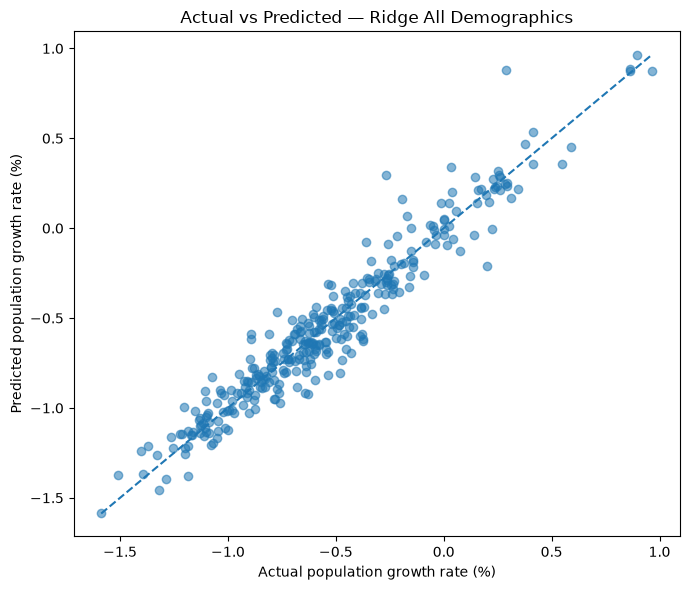

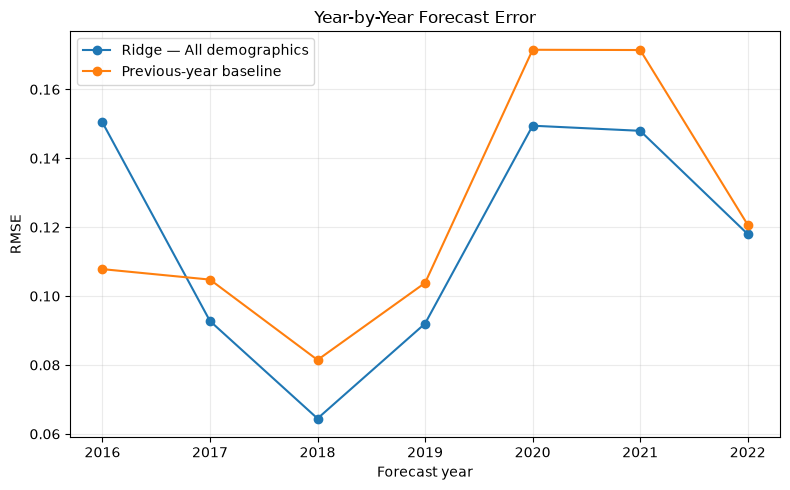

LARGEST ABSOLUTE ERRORS


,Year,Actual,Predicted,Error,Absolute Error
1798,2020,0.2898,0.8802,0.5904,0.5904
2174,2021,-0.2676,0.2975,0.5651,0.5651
2550,2022,0.1999,-0.2104,-0.4103,0.4103
1808,2020,-0.1930,0.1638,0.3568,0.3568
313,2016,-0.4828,-0.8053,-0.3226,0.3226
1427,2019,-0.7722,-0.4636,0.3086,0.3086
664,2017,-0.8933,-0.5908,0.3025,0.3025
2208,2021,0.0354,0.3377,0.3023,0.3023
2581,2022,-0.6284,-0.9205,-0.2921,0.2921
2188,2021,-0.3585,-0.0760,0.2826,0.2826


In [143]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

chosen_name = "Ridge — All demographics"

# Extract out-of-sample predictions for the selected model
chosen = feature_predictions[
    feature_predictions["Model"] == chosen_name
].copy()

# Extract baseline predictions for the same years
baseline = feature_predictions[
    feature_predictions["Model"] == "Previous-year baseline"
].copy()

chosen["Error"] = chosen["Predicted"] - chosen["Actual"]
chosen["Absolute Error"] = chosen["Error"].abs()

print("SELECTED MODEL — SUMMARY")
print("Observations:", len(chosen))
print("MAE:", round(mean_absolute_error(
    chosen["Actual"], chosen["Predicted"]
), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(
    chosen["Actual"], chosen["Predicted"]
)), 4))
print("R²:", round(r2_score(
    chosen["Actual"], chosen["Predicted"]
), 4))
print("Mean prediction error:", round(
    chosen["Error"].mean(), 4
))

# 1. Actual versus predicted
fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(
    chosen["Actual"],
    chosen["Predicted"],
    alpha=0.55
)

lower = min(chosen["Actual"].min(), chosen["Predicted"].min())
upper = max(chosen["Actual"].max(), chosen["Predicted"].max())

ax.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--"
)

ax.set_xlabel("Actual population growth rate (%)")
ax.set_ylabel("Predicted population growth rate (%)")
ax.set_title("Actual vs Predicted — Ridge All Demographics")
plt.tight_layout()
plt.show()

# 2. Year-by-year RMSE comparison
def calculate_yearly_rmse(frame):
    return frame.groupby("Year").apply(
        lambda g: np.sqrt(mean_squared_error(
            g["Actual"], g["Predicted"]
        )),
        include_groups=False
    )

ridge_yearly_rmse = calculate_yearly_rmse(chosen)
baseline_yearly_rmse = calculate_yearly_rmse(baseline)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    ridge_yearly_rmse.index,
    ridge_yearly_rmse.values,
    marker="o",
    label="Ridge — All demographics"
)

ax.plot(
    baseline_yearly_rmse.index,
    baseline_yearly_rmse.values,
    marker="o",
    label="Previous-year baseline"
)

ax.set_xlabel("Forecast year")
ax.set_ylabel("RMSE")
ax.set_title("Year-by-Year Forecast Error")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

# 3. Show the largest prediction errors
print("LARGEST ABSOLUTE ERRORS")
display(
    chosen[
        ["Year", "Actual", "Predicted", "Error", "Absolute Error"]
    ]
    .sort_values("Absolute Error", ascending=False)
    .head(15)
    .round(4)
)

In [144]:
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# --------------------------------------------------
# 1. Prepare the classification dataset
# --------------------------------------------------

class_df = forecast_df.copy()

if "Population Decline" not in class_df.columns:
    raise KeyError(
        "'Population Decline' is missing from forecast_df."
    )

class_df = class_df.sort_values(
    ["Region Code", "Time"]
).copy()

class_target = "Population Decline"

class_df[class_target] = pd.to_numeric(
    class_df[class_target], errors="coerce"
)

# Check that the target contains only binary labels
labels_found = set(
    class_df[class_target].dropna().unique()
)

if not labels_found.issubset({0, 1, 0.0, 1.0}):
    raise ValueError(
        f"Expected binary labels 0 and 1; found {labels_found}"
    )

# Verify whether decline is defined as growth below zero
valid_labels = class_df.dropna(
    subset=[class_target, target]
)

expected_label = (
    valid_labels[target] < 0
).astype(int)

mismatch_count = int(
    (
        valid_labels[class_target].astype(int)
        != expected_label
    ).sum()
)

print(
    "Labels inconsistent with growth < 0:",
    mismatch_count
)

# Previous-year information
class_df["Previous-Year Growth Rate"] = (
    class_df.groupby("Region Code")[target].shift(1)
)

class_df["Previous-Year Decline"] = (
    class_df.groupby("Region Code")[class_target].shift(1)
)

predictors = [
    "Previous-Year Growth Rate",
    *forecast_features
]

# Remove rows without a usable target or prior-year information
class_df = class_df.dropna(
    subset=[
        class_target,
        "Previous-Year Decline",
        *predictors
    ]
).copy()

class_df[class_target] = (
    class_df[class_target].astype(int)
)

# --------------------------------------------------
# 2. Chronological train/test split
# --------------------------------------------------

class_train = class_df[
    class_df["Time"] <= 2019
].copy()

class_test = class_df[
    class_df["Time"] >= 2020
].copy()

X_train = class_train[predictors]
y_train = class_train[class_target]

X_test = class_test[predictors]
y_test = class_test[class_target]

print("\nTraining observations:", len(class_train))
print("Test observations:", len(class_test))

print(
    "Training period:",
    int(class_train["Time"].min()),
    "to",
    int(class_train["Time"].max())
)

print(
    "Test period:",
    int(class_test["Time"].min()),
    "to",
    int(class_test["Time"].max())
)

print(
    "\nTraining decline rate:",
    round(y_train.mean(), 3)
)

print(
    "Test decline rate:",
    round(y_test.mean(), 3)
)

# --------------------------------------------------
# 3. Fit classification models
# --------------------------------------------------

class_models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Random Forest Classifier": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=500,
            max_depth=5,
            min_samples_leaf=5,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

for name, model in class_models.items():
    model.fit(X_train, y_train)

# --------------------------------------------------
# 4. Generate predictions and scores
# --------------------------------------------------

class_predictions = pd.DataFrame(index=class_test.index)

class_predictions["Actual"] = y_test
class_predictions["Previous-Year Baseline"] = (
    class_test["Previous-Year Decline"].astype(int)
)

majority_label = int(y_train.mode().iloc[0])

class_predictions["Majority-Class Baseline"] = (
    majority_label
)

probability_scores = {}

for name, model in class_models.items():
    class_predictions[name] = model.predict(X_test)

    # Probability that the prefecture experiences decline (class 1)
    positive_index = list(
        model.named_steps["model"].classes_
    ).index(1)

    probability_scores[name] = model.predict_proba(
        X_test
    )[:, positive_index]

# --------------------------------------------------
# 5. Evaluate predictions
# --------------------------------------------------

def classification_metrics(actual, predicted, scores=None):
    result = {
        "Accuracy": accuracy_score(actual, predicted),
        "Balanced Accuracy": balanced_accuracy_score(
            actual, predicted
        ),
        "Precision (decline)": precision_score(
            actual, predicted, zero_division=0
        ),
        "Recall (decline)": recall_score(
            actual, predicted, zero_division=0
        ),
        "F1 (decline)": f1_score(
            actual, predicted, zero_division=0
        )
    }

    result["ROC-AUC"] = (
        roc_auc_score(actual, scores)
        if scores is not None and actual.nunique() == 2
        else np.nan
    )

    return result

class_results = {}

# Baselines
for name in [
    "Previous-Year Baseline",
    "Majority-Class Baseline"
]:
    class_results[name] = classification_metrics(
        class_predictions["Actual"],
        class_predictions[name],
        class_predictions[name].astype(float)
    )

# ML models
for name in class_models:
    class_results[name] = classification_metrics(
        class_predictions["Actual"],
        class_predictions[name],
        probability_scores[name]
    )

class_results_df = pd.DataFrame(class_results).T

print("\nCLASSIFICATION PERFORMANCE — 2020–2025")
display(class_results_df.round(4))

Labels inconsistent with growth < 0: 0


NameError: name 'forecast_features' is not defined